In [1]:
# ============================================================
# CELL 1: Environment Check
# ============================================================
import torch, transformers, sklearn, pandas as pd, numpy as np, sys

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("scikit-learn:", sklearn.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

C:\Users\CH.SC.U4CSE23160\Final_Year_Project\bert_env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.10.11
PyTorch: 2.6.0+cu126
Transformers: 5.15.1
scikit-learn: 1.7.2
CUDA available: True
GPU: NVIDIA GeForce RTX 3070
VRAM: 8.0 GB


In [2]:
# ============================================================
# CELL 2: Imports, Config, HF Token, Device Setup
# ============================================================
from pathlib import Path
import json, random, gc, warnings
import numpy as np, pandas as pd, torch, torch.nn as nn

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, classification_report,
    confusion_matrix, f1_score, cohen_kappa_score, matthews_corrcoef,
    log_loss, roc_auc_score, top_k_accuracy_score,
)
from sklearn.utils.class_weight import compute_class_weight

from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification, Trainer,
    TrainingArguments, EarlyStoppingCallback, set_seed,
)

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# HUGGING FACE TOKEN  (replace with your token)
# ------------------------------------------------------------
HF_TOKEN = os.getenv("HF_TOKEN")
# ------------------------------------------------------------
BASE_DIR = Path(r"C:/Users/CH.SC.U4CSE23160/Neural Project/IndicHallbench-Hallucinations-Benchmark")
DATA_PATH       = BASE_DIR / "data/annotations/final/final_annotations.csv"
RESPONSES_PATH  = BASE_DIR / "data/annotations/working/responses.json"
REFERENCES_PATH = BASE_DIR / "data/annotations/working/references.json"

# ------------------------------------------------------------
# OUTPUT DIRECTORY — renamed for MuRIL
# ------------------------------------------------------------
OUTPUT_DIR = BASE_DIR / "results/muril_base_full_dataset"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# MODEL — MuRIL (base)
# ------------------------------------------------------------
MODEL_NAME  = "google/muril-base-cased"
MAX_LENGTH  = 256
TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE  = 32
GRADIENT_ACCUMULATION_STEPS = 1
EPOCHS = 15
LEARNING_RATE = 2e-5
WEIGHT_DECAY  = 0.01
WARMUP_RATIO  = 0.1
MAX_GRAD_NORM = 1.0
SEED = 42

set_seed(SEED); random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "| Model:", MODEL_NAME, "| Output:", OUTPUT_DIR)

Device: cuda | Model: google/muril-base-cased | Output: C:\Users\CH.SC.U4CSE23160\Neural Project\IndicHallbench-Hallucinations-Benchmark\results\muril_base_full_dataset


In [3]:
# ============================================================
# CELL 3: Load Raw Data and Inspect
# ============================================================
responses_df   = pd.read_json(RESPONSES_PATH)
references_df  = pd.read_json(REFERENCES_PATH)
annotations_df = pd.read_csv(DATA_PATH)

print("responses:  ", responses_df.shape)
print("references: ", references_df.shape)
print("annotations:", annotations_df.shape)

print("\nLanguage distribution in responses:")
print(responses_df["language"].value_counts())
print("\nModel distribution in responses:")
print(responses_df["model_name"].value_counts())
print("\nAnnotation correctness_label:")
print(annotations_df["correctness_label"].value_counts(dropna=False))

responses:   (64800, 10)
references:  (10800, 11)
annotations: (64800, 20)

Language distribution in responses:
language
EN       10800
HI       10800
HI-EN    10800
NE       10800
TA       10800
TE       10800
Name: count, dtype: int64

Model distribution in responses:
model_name
GPT-5.6 Luna           10800
Claude Sonnet 5.5      10800
DeepSeek-V4.1-Flash    10800
Gemini 3               10800
Qwen 3.7               10800
GLM-5.3 Flash          10800
Name: count, dtype: int64

Annotation correctness_label:
correctness_label
Correct              39459
Incorrect            13092
Partially Correct    12249
Name: count, dtype: int64


In [4]:
# ============================================================
# CELL 4: Merge DataFrames with Validation
# ============================================================
for df in [responses_df, references_df, annotations_df]:
    if "question_id" in df.columns:
        df["question_id"] = df["question_id"].astype("string").str.strip()
    if "language" in df.columns:
        df["language"] = df["language"].astype("string").str.strip().str.upper()
    if "model_name" in df.columns:
        df["model_name"] = df["model_name"].astype("string").str.strip()

LANGUAGE_ALIASES = {"HIEN": "HI-EN", "HI_EN": "HI-EN", "HINGLISH": "HI-EN"}
for df in [responses_df, annotations_df]:
    df["language"] = df["language"].replace(LANGUAGE_ALIASES)

assert references_df["question_id"].is_unique, "references has duplicate question_id!"

KEYS = ["question_id", "language", "model_name"]
assert not responses_df.duplicated(KEYS).any(), "responses has duplicate keys"
assert not annotations_df.duplicated(KEYS).any(), "annotations has duplicate keys"

refs_slim = references_df.drop(
    columns=["fact_id", "domain", "difficulty", "source_url"], errors="ignore"
)

merged = responses_df.merge(
    refs_slim,
    on="question_id",
    how="left",
    validate="many_to_one",
    suffixes=("_resp", "_ref"),
    indicator=True,
)
print("Responses ↔ References match:")
print(merged["_merge"].value_counts())
if (merged["_merge"] != "both").any():
    raise ValueError("Some responses have no reference match!")
merged.drop(columns="_merge", inplace=True)

ann_slim = annotations_df[KEYS + [
    "response_id", "correctness_label", "hallucination_types",
    "severity", "confidence", "judge_model",
]].copy()

merged = merged.merge(
    ann_slim,
    on=KEYS,
    how="left",
    validate="one_to_one",
    indicator=True,
)
print("\nMerged ↔ Annotations match:")
print(merged["_merge"].value_counts())
if (merged["_merge"] != "both").any():
    raise ValueError("Some rows have no annotation.")
merged.drop(columns="_merge", inplace=True)

print("\nFinal merged rows:", len(merged))
print("Missing correctness_label:", merged["correctness_label"].isna().sum())
print("\ncorrectness_label distribution:")
print(merged["correctness_label"].value_counts(dropna=False))
print("\nColumns:", merged.columns.tolist())

Responses ↔ References match:
_merge
both          64800
left_only         0
right_only        0
Name: count, dtype: int64

Merged ↔ Annotations match:
_merge
both          64800
left_only         0
right_only        0
Name: count, dtype: int64

Final merged rows: 64800
Missing correctness_label: 0

correctness_label distribution:
correctness_label
Correct              39459
Incorrect            13092
Partially Correct    12249
Name: count, dtype: int64

Columns: ['question_id', 'fact_id', 'domain', 'difficulty', 'fact_type', 'language', 'model_name', 'response', 'timestamp', 'source_url', 'question_type', 'question', 'ground_truth', 'answer_type', 'answer_length_category', 'primary_hallucination_type', 'response_id', 'correctness_label', 'hallucination_types', 'severity', 'confidence', 'judge_model']


In [5]:
# ============================================================
# CELL 5: Text Cleaning, Label Encoding, Input Construction
# ============================================================
for col in ["question", "ground_truth", "response"]:
    merged[col] = merged[col].fillna("").astype(str).str.strip()

before = len(merged)
merged = merged[
    (merged["question"] != "") &
    (merged["ground_truth"] != "") &
    (merged["response"] != "")
].copy()
print(f"Removed {before - len(merged)} rows with empty text.")

LABEL_FIX = {
    "correct": "Correct",
    "incorrect": "Incorrect",
    "partially correct": "Partially Correct",
    "partial": "Partially Correct",
    "uncertain": "Uncertain",
}
merged["correctness_label"] = (
    merged["correctness_label"].astype("string").str.strip().replace(LABEL_FIX)
)

VALID_LABELS = ["Correct", "Partially Correct", "Incorrect", "Uncertain"]
bad = sorted(set(merged["correctness_label"].dropna()) - set(VALID_LABELS))
if bad:
    raise ValueError(f"Unexpected labels: {bad}")

merged = merged.dropna(subset=["correctness_label"]).copy()
print("Final rows:", len(merged))
print("\nLabel distribution:")
print(merged["correctness_label"].value_counts())

def build_input(row):
    return (
        f"Question: {row['question']}\n"
        f"Ground Truth: {row['ground_truth']}\n"
        f"Model Response: {row['response']}"
    )

merged["input_text"] = merged.apply(build_input, axis=1)

label_encoder = LabelEncoder()
merged["label"] = label_encoder.fit_transform(merged["correctness_label"])
LABELS     = list(label_encoder.classes_)
NUM_LABELS = len(LABELS)

print("\nLabel mapping:")
for i, lbl in enumerate(LABELS):
    print(f"  {i} = {lbl}")

Removed 0 rows with empty text.
Final rows: 64800

Label distribution:
correctness_label
Correct              39459
Incorrect            13092
Partially Correct    12249
Name: count, dtype: Int64

Label mapping:
  0 = Correct
  1 = Incorrect
  2 = Partially Correct


In [6]:
# ============================================================
# CELL 6: Stratified Group Splits (Train/Dev/Test)
# ============================================================
def pick_fact_id_col(df):
    for candidate in ["fact_id", "fact_id_resp", "fact_id_ref",
                      "fact_id_response", "fact_id_reference"]:
        if candidate in df.columns:
            return candidate
    return None

fact_col = pick_fact_id_col(merged)
if fact_col is None:
    print("No fact_id column found — falling back to question_id as split group.")
    merged["split_group"] = "QUESTION_" + merged["question_id"].astype(str)
else:
    fact_ids = merged[fact_col].astype(str).str.strip()
    invalid_mask = fact_ids.isin(["", "nan", "None", "<NA>"]) | merged[fact_col].isna()
    merged["split_group"] = np.where(
        ~invalid_mask,
        "FACT_" + fact_ids,
        "QUESTION_" + merged["question_id"].astype(str),
    )

print("Unique split groups:", merged["split_group"].nunique())
print("Unique facts in responses:", merged["split_group"].str.startswith("FACT_").sum(),
      "rows |", merged.loc[merged["split_group"].str.startswith("FACT_"),
                           "split_group"].nunique(), "unique facts")

sgkf_test = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
folds = list(sgkf_test.split(
    merged["input_text"], merged["label"], groups=merged["split_group"]
))
test_pos      = np.concatenate([folds[i][1] for i in range(3)])
remaining_idx = np.setdiff1d(np.arange(len(merged)), test_pos)

remaining = merged.iloc[remaining_idx].reset_index(drop=True)
test_df   = merged.iloc[test_pos].reset_index(drop=True).copy()

sgkf_dev = StratifiedGroupKFold(n_splits=17, shuffle=True, random_state=SEED + 1)
dev_folds = list(sgkf_dev.split(
    remaining["input_text"], remaining["label"], groups=remaining["split_group"]
))
dev_pos = np.concatenate([dev_folds[i][1] for i in range(3)])

dev_df   = remaining.iloc[dev_pos].reset_index(drop=True).copy()
train_df = remaining.drop(index=remaining.index[dev_pos]).reset_index(drop=True).copy()

assert set(train_df["split_group"]).isdisjoint(set(dev_df["split_group"])), "Leakage: train ∩ dev"
assert set(train_df["split_group"]).isdisjoint(set(test_df["split_group"])), "Leakage: train ∩ test"
assert set(dev_df["split_group"]).isdisjoint(set(test_df["split_group"])), "Leakage: dev ∩ test"

total = len(merged)
print(f"\nTrain: {len(train_df):>6,} ({len(train_df)/total*100:.2f}%)")
print(f"Dev:   {len(dev_df):>6,} ({len(dev_df)/total*100:.2f}%)")
print(f"Test:  {len(test_df):>6,} ({len(test_df)/total*100:.2f}%)")
print("Group leakage check: PASSED")

print("\nClass distribution per split (%):")
for name, part in [("Train", train_df), ("Dev", dev_df), ("Test", test_df)]:
    vc = part["correctness_label"].value_counts(normalize=True).mul(100).round(2)
    print(f"  {name:5s}: {dict(vc)}")

Unique split groups: 10800
Unique facts in responses: 10800 rows | 1800 unique facts

Train: 45,360 (70.00%)
Dev:    9,720 (15.00%)
Test:   9,720 (15.00%)
Group leakage check: PASSED

Class distribution per split (%):
  Train: {'Correct': np.float64(61.29), 'Incorrect': np.float64(19.98), 'Partially Correct': np.float64(18.73)}
  Dev  : {'Correct': np.float64(59.43), 'Incorrect': np.float64(21.07), 'Partially Correct': np.float64(19.5)}
  Test : {'Correct': np.float64(60.51), 'Incorrect': np.float64(20.39), 'Partially Correct': np.float64(19.09)}


In [7]:
# ============================================================
# CELL 7: Compute Class Weights
# ============================================================
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_LABELS),
    y=train_df["label"].to_numpy(),
)
class_weights = torch.tensor(class_weights, dtype=torch.float).to(DEVICE)

print("Class weights (inverse frequency):")
for i, w in enumerate(class_weights.cpu().numpy()):
    print(f"  {LABELS[i]:20s}  ->  {w:.3f}")

Class weights (inverse frequency):
  Correct               ->  0.544
  Incorrect             ->  1.669
  Partially Correct     ->  1.779


In [8]:
# ============================================================
# CELL 8: Tokenizer + Dataset (MuRIL with HF_TOKEN)
# ============================================================
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, token=HF_TOKEN)

class HallucinationDataset(torch.utils.data.Dataset):
    def __init__(self, df):
        self.enc = tokenizer(
            df["input_text"].tolist(),
            truncation=True, padding="max_length",
            max_length=MAX_LENGTH, return_tensors="pt",
        )
        self.labels = df["label"].tolist()

    def __len__(self): return len(self.labels)

    def __getitem__(self, idx):
        item = {k: v[idx] for k, v in self.enc.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

train_dataset = HallucinationDataset(train_df)
dev_dataset   = HallucinationDataset(dev_df)
test_dataset  = HallucinationDataset(test_df)

print(f"Train: {len(train_dataset):,} | Dev: {len(dev_dataset):,} | Test: {len(test_dataset):,}")

Train: 45,360 | Dev: 9,720 | Test: 9,720


In [9]:
# ============================================================
# CELL 9: Model + Weighted Trainer (MuRIL with HF_TOKEN)
# ============================================================
class WeightedTrainer(Trainer):
    """Trainer with class-balanced cross-entropy loss."""
    def __init__(self, class_weights=None, **kwargs):
        super().__init__(**kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kw):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits  = outputs.logits
        loss = nn.CrossEntropyLoss(weight=self.class_weights)(
            logits.view(-1, model.config.num_labels), labels.view(-1)
        )
        return (loss, outputs) if return_outputs else loss


id2label = {i: l for i, l in enumerate(LABELS)}
label2id = {l: i for i, l in enumerate(LABELS)}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    id2label=id2label,
    label2id=label2id,
    token=HF_TOKEN,
).to(DEVICE)
print("Model loaded.")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 15307.12it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/archit

Model loaded.


In [10]:
# ============================================================
# CELL 10: Compute Metrics Function
# ============================================================
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = torch.softmax(torch.tensor(logits), dim=-1).numpy()
    preds = np.argmax(logits, axis=-1)

    p, r, mf1, _ = precision_recall_fscore_support(labels, preds,
                                                   average="macro", zero_division=0)
    wf1 = f1_score(labels, preds, average="weighted", zero_division=0)

    def safe(fn):
        try: return fn()
        except Exception: return float("nan")

    return {
        "accuracy":        accuracy_score(labels, preds),
        "macro_precision": p,
        "macro_recall":    r,
        "macro_f1":        mf1,
        "weighted_f1":     wf1,
        "cohen_kappa":     safe(lambda: cohen_kappa_score(labels, preds)),
        "mcc":             safe(lambda: matthews_corrcoef(labels, preds)),
        "log_loss":        safe(lambda: log_loss(labels, probs,
                                                labels=list(range(NUM_LABELS)))),
        "roc_auc_macro":   safe(lambda: roc_auc_score(
            labels, probs, multi_class="ovr", average="macro",
            labels=list(range(NUM_LABELS)))),
        "top2_accuracy":   safe(lambda: top_k_accuracy_score(
            labels, probs, k=min(2, NUM_LABELS),
            labels=list(range(NUM_LABELS)))),
    }

In [11]:
# ============================================================
# CELL 11: Training Arguments + Trainer Setup
# ============================================================
steps_per_epoch = int(np.ceil(
    len(train_dataset) / (TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS)
))
total_steps  = steps_per_epoch * EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)
print(f"Steps/epoch: {steps_per_epoch} | Total: {total_steps} | Warmup: {warmup_steps}")

training_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR / "checkpoints"),
    num_train_epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    warmup_steps=warmup_steps,
    max_grad_norm=MAX_GRAD_NORM,

    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,

    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=3,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,

    logging_strategy="steps",
    logging_steps=50,
    logging_first_step=True,
    disable_tqdm=False,

    fp16=torch.cuda.is_available(),
    dataloader_num_workers=0,

    report_to="none",
    seed=SEED, data_seed=SEED,
)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=dev_dataset,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
    class_weights=class_weights,
    callbacks=[
        EarlyStoppingCallback(early_stopping_patience=3),
    ],
)
print("Trainer ready.")

Steps/epoch: 2835 | Total: 42525 | Warmup: 4252
Trainer ready.


In [12]:
# ============================================================
# CELL 12: Train the Model
# ============================================================
train_result = trainer.train()
print("\nTraining done:", train_result.metrics)
trainer.save_model(OUTPUT_DIR / "best_model")
tokenizer.save_pretrained(OUTPUT_DIR / "best_model")

Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Cohen Kappa,Mcc,Log Loss,Roc Auc Macro,Top2 Accuracy,Runtime,Samples Per Second,Steps Per Second
1,0.707839,0.729484,0.735288,0.672977,0.701373,0.683403,0.740823,0.550162,0.553708,0.678875,0.873847,0.913374,22.282200,436.223000,13.643000
2,0.503561,0.651499,0.766564,0.723755,0.754427,0.732169,0.774808,0.607327,0.613753,0.601902,0.901948,0.937140,22.482200,432.341000,13.522000
3,0.470806,0.724733,0.795062,0.748340,0.742778,0.745143,0.795098,0.635471,0.635657,0.588208,0.909187,0.948868,22.342300,435.049000,13.606000
4,0.372355,0.907254,0.799588,0.755320,0.728019,0.736858,0.792849,0.634583,0.637370,0.652187,0.907993,0.955761,22.209800,437.645000,13.688000
5,0.353585,0.970167,0.798765,0.757849,0.720006,0.734707,0.791361,0.629017,0.632732,0.684170,0.908105,0.953189,22.235500,437.139000,13.672000
6,0.270550,1.136420,0.801955,0.762914,0.741942,0.750052,0.801081,0.643799,0.644992,0.848550,0.910699,0.957613,22.054300,440.730000,13.784000
7,0.187811,1.197470,0.803704,0.761463,0.743015,0.751299,0.801988,0.646298,0.647054,0.885618,0.909007,0.952984,21.949000,442.845000,13.850000
8,0.212281,1.423589,0.797634,0.762715,0.717021,0.735905,0.790902,0.624927,0.629281,0.984721,0.908545,0.951955,22.079000,440.238000,13.769000
9,0.149444,1.520697,0.801337,0.762813,0.741005,0.749399,0.800327,0.642408,0.643681,1.133113,0.900487,0.947222,22.150000,438.827000,13.725000
10,0.100364,1.905285,0.797016,0.765993,0.709123,0.731722,0.788890,0.620251,0.626656,1.289901,0.896942,0.944547,22.036500,441.087000,13.795000


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.55it/s]



Training done: {'train_runtime': 5394.0736, 'train_samples_per_second': 126.138, 'train_steps_per_second': 7.884, 'total_flos': 5.96741231407104e+16, 'train_loss': 0.35501517643583724, 'epoch': 10.0}


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.39it/s]


('C:\\Users\\CH.SC.U4CSE23160\\Neural Project\\IndicHallbench-Hallucinations-Benchmark\\results\\muril_base_full_dataset\\best_model\\tokenizer_config.json',
 'C:\\Users\\CH.SC.U4CSE23160\\Neural Project\\IndicHallbench-Hallucinations-Benchmark\\results\\muril_base_full_dataset\\best_model\\tokenizer.json')

In [13]:

# ============================================================
# CELL 13: COMPREHENSIVE TEST SET EVALUATION
# ============================================================

# Required imports
import numpy as np
import torch
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    log_loss,
    top_k_accuracy_score,
    balanced_accuracy_score
)

# ------------------------------------------------------------
# 1. Generate test predictions
# ------------------------------------------------------------

test_results = trainer.predict(test_dataset)

test_logits = np.asarray(test_results.predictions)
test_true = np.asarray(test_results.label_ids)

# Handle tuple predictions if returned by the model
if isinstance(test_results.predictions, tuple):
    test_logits = np.asarray(test_results.predictions[0])

test_probs = torch.softmax(
    torch.tensor(test_logits, dtype=torch.float32),
    dim=-1
).cpu().numpy()

test_preds = np.argmax(test_logits, axis=1)

class_labels = list(range(NUM_LABELS))

# ------------------------------------------------------------
# 2. Classification report
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("TEST SET CLASSIFICATION REPORT")
print("=" * 65)

print(classification_report(
    test_true,
    test_preds,
    labels=class_labels,
    target_names=LABELS,
    digits=4,
    zero_division=0
))

# ------------------------------------------------------------
# 3. Classification metrics
# ------------------------------------------------------------

test_acc = accuracy_score(test_true, test_preds)

test_precision_macro = precision_score(
    test_true, test_preds,
    average="macro",
    zero_division=0
)

test_precision_weighted = precision_score(
    test_true, test_preds,
    average="weighted",
    zero_division=0
)

test_recall_macro = recall_score(
    test_true, test_preds,
    average="macro",
    zero_division=0
)

test_recall_weighted = recall_score(
    test_true, test_preds,
    average="weighted",
    zero_division=0
)

test_mf1 = f1_score(
    test_true, test_preds,
    average="macro",
    zero_division=0
)

test_wf1 = f1_score(
    test_true, test_preds,
    average="weighted",
    zero_division=0
)

test_balanced_acc = balanced_accuracy_score(
    test_true, test_preds
)

test_kap = cohen_kappa_score(test_true, test_preds)

test_mcc = matthews_corrcoef(test_true, test_preds)

# ------------------------------------------------------------
# 4. ROC-AUC
# ------------------------------------------------------------

try:
    if NUM_LABELS == 2:
        test_auc = roc_auc_score(
            test_true,
            test_probs[:, 1]
        )
    else:
        test_auc = roc_auc_score(
            test_true,
            test_probs,
            multi_class="ovr",
            average="macro",
            labels=class_labels
        )
except ValueError as e:
    print(f"ROC-AUC warning: {e}")
    test_auc = float("nan")

# ------------------------------------------------------------
# 5. Log Loss
# ------------------------------------------------------------

try:
    test_ll = log_loss(
        test_true,
        test_probs,
        labels=class_labels
    )
except ValueError as e:
    print(f"Log Loss warning: {e}")
    test_ll = float("nan")

# ------------------------------------------------------------
# 6. Top-2 Accuracy
# ------------------------------------------------------------

try:
    test_top2 = top_k_accuracy_score(
        test_true,
        test_probs,
        k=min(2, NUM_LABELS),
        labels=class_labels
    )
except ValueError as e:
    print(f"Top-2 Accuracy warning: {e}")
    test_top2 = float("nan")

# ------------------------------------------------------------
# 7. Display complete results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FINAL TEST SET PERFORMANCE")
print("=" * 65)

print(f"Accuracy:              {test_acc:.4f}")
print(f"Macro Precision:       {test_precision_macro:.4f}")
print(f"Weighted Precision:    {test_precision_weighted:.4f}")
print(f"Macro Recall:          {test_recall_macro:.4f}")
print(f"Weighted Recall:       {test_recall_weighted:.4f}")
print(f"Macro F1:              {test_mf1:.4f}")
print(f"Weighted F1:           {test_wf1:.4f}")
print(f"Balanced Accuracy:     {test_balanced_acc:.4f}")
print(f"Cohen's Kappa:         {test_kap:.4f}")
print(f"MCC:                   {test_mcc:.4f}")
print(f"ROC-AUC (Macro):       {test_auc:.4f}")
print(f"Log Loss:              {test_ll:.4f}")
print(f"Top-2 Accuracy:        {test_top2:.4f}")

# ------------------------------------------------------------
# 8. Save results
# ------------------------------------------------------------

test_metrics_dict = {
    "Accuracy": test_acc,
    "Macro Precision": test_precision_macro,
    "Weighted Precision": test_precision_weighted,
    "Macro Recall": test_recall_macro,
    "Weighted Recall": test_recall_weighted,
    "Macro F1": test_mf1,
    "Weighted F1": test_wf1,
    "Balanced Accuracy": test_balanced_acc,
    "Cohen's Kappa": test_kap,
    "MCC": test_mcc,
    "ROC-AUC (Macro)": test_auc,
    "Log Loss": test_ll,
    "Top-2 Accuracy": test_top2
}

test_metrics_df = pd.DataFrame([test_metrics_dict])

display(test_metrics_df.round(4))

test_metrics_df.to_csv(
    "test_set_evaluation_metrics.csv",
    index=False
)

print("\nTest evaluation completed successfully.")
print("Saved: test_set_evaluation_metrics.csv")


TEST SET CLASSIFICATION REPORT
                   precision    recall  f1-score   support

          Correct     0.8703    0.8977    0.8838      5882
        Incorrect     0.7693    0.6746    0.7188      1982
Partially Correct     0.6225    0.6422    0.6322      1856

         accuracy                         0.8034      9720
        macro avg     0.7540    0.7382    0.7449      9720
     weighted avg     0.8024    0.8034    0.8021      9720


FINAL TEST SET PERFORMANCE
Accuracy:              0.8034
Macro Precision:       0.7540
Weighted Precision:    0.8024
Macro Recall:          0.7382
Weighted Recall:       0.8034
Macro F1:              0.7449
Weighted F1:           0.8021
Balanced Accuracy:     0.7382
Cohen's Kappa:         0.6414
MCC:                   0.6420
ROC-AUC (Macro):       0.9090
Log Loss:              0.8974
Top-2 Accuracy:        0.9471


,Accuracy,Macro Precision,Weighted Precision,Macro Recall,Weighted Recall,Macro F1,Weighted F1,Balanced Accuracy,Cohen's Kappa,MCC,ROC-AUC (Macro),Log Loss,Top-2 Accuracy
0,0.8034,0.754,0.8024,0.7382,0.8034,0.7449,0.8021,0.7382,0.6414,0.642,0.909,0.8974,0.9471



Test evaluation completed successfully.
Saved: test_set_evaluation_metrics.csv


In [14]:
# ============================================================
# CELL 14: Per-Class Metrics
# ============================================================
p, r, f, sup = precision_recall_fscore_support(
    test_true, test_preds, labels=list(range(NUM_LABELS)), zero_division=0
)
per_class = pd.DataFrame({
    "label": LABELS, "precision": p, "recall": r, "f1": f, "support": sup,
})
print(per_class.round(4))
per_class.to_csv(OUTPUT_DIR / "per_class_metrics.csv", index=False)

               label  precision  recall      f1  support
0            Correct     0.8703  0.8977  0.8838     5882
1          Incorrect     0.7693  0.6746  0.7188     1982
2  Partially Correct     0.6225  0.6422  0.6322     1856


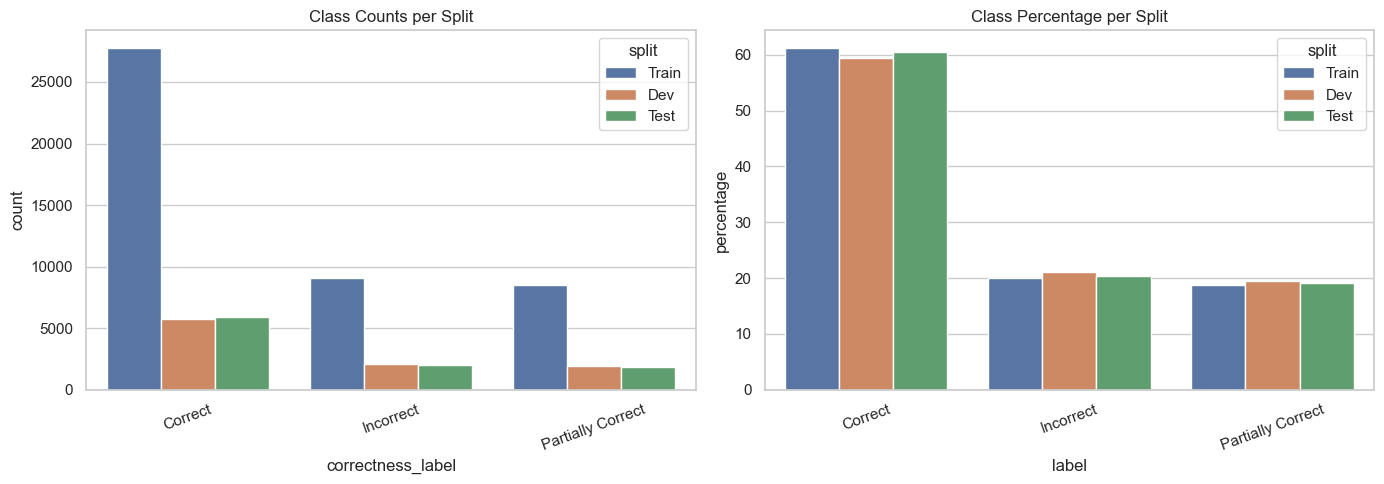

In [15]:
# ============================================================
# CELL 15: Split Distribution Visualization
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

records = []
for name, part in [("Train", train_df), ("Dev", dev_df), ("Test", test_df)]:
    vc = part["correctness_label"].value_counts()
    for lbl in LABELS:
        records.append({
            "split": name, "label": lbl,
            "count": int(vc.get(lbl, 0)),
            "percentage": vc.get(lbl, 0) / len(part) * 100,
        })
split_dist = pd.DataFrame(records)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
combined = pd.concat([
    train_df.assign(split="Train"),
    dev_df.assign(split="Dev"),
    test_df.assign(split="Test"),
])
sns.countplot(data=combined, x="correctness_label", hue="split",
              order=LABELS, ax=axes[0])
axes[0].set_title("Class Counts per Split")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=split_dist, x="label", y="percentage", hue="split",
            order=LABELS, ax=axes[1])
axes[1].set_title("Class Percentage per Split")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "split_distribution.png", dpi=300, bbox_inches="tight")
plt.show()
split_dist.to_csv(OUTPUT_DIR / "split_class_distribution.csv", index=False)

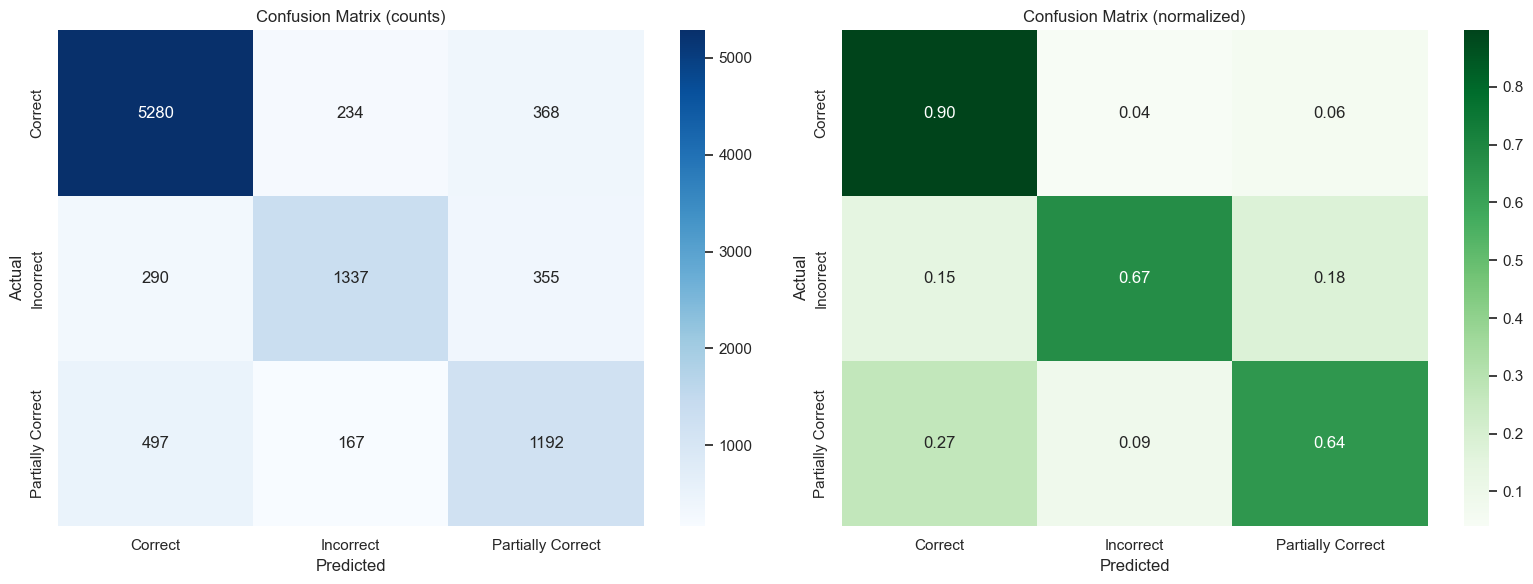

In [16]:
# ============================================================
# CELL 16: Confusion Matrix Visualization
# ============================================================
cm      = confusion_matrix(test_true, test_preds, labels=list(range(NUM_LABELS)))
cm_norm = cm.astype("float") / np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=LABELS, yticklabels=LABELS, ax=axes[0])
axes[0].set_title("Confusion Matrix (counts)")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Greens",
            xticklabels=LABELS, yticklabels=LABELS, ax=axes[1])
axes[1].set_title("Confusion Matrix (normalized)")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

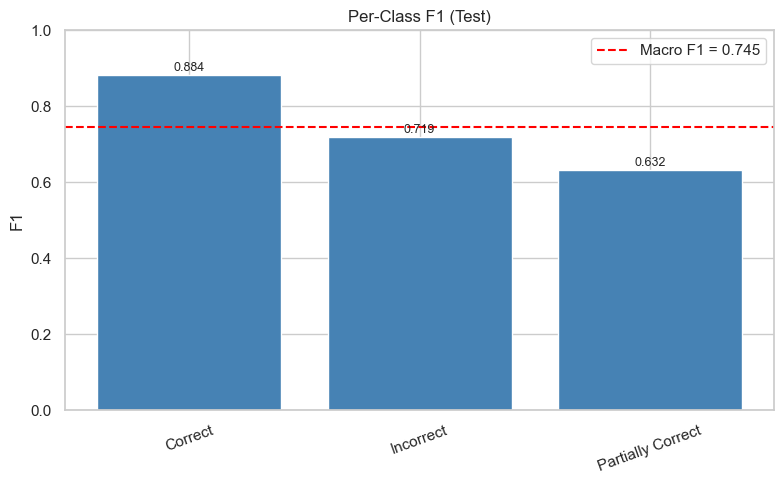

In [17]:
# ============================================================
# CELL 17: Per-Class F1 Bar Chart
# ============================================================
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(per_class["label"], per_class["f1"], color="steelblue")
ax.axhline(test_mf1, color="red", linestyle="--", label=f"Macro F1 = {test_mf1:.3f}")
ax.set_ylim(0, 1); ax.set_ylabel("F1"); ax.set_title("Per-Class F1 (Test)")
ax.tick_params(axis="x", rotation=20)
for b, v in zip(bars, per_class["f1"]):
    ax.text(b.get_x() + b.get_width()/2, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "per_class_f1.png", dpi=300, bbox_inches="tight")
plt.show()

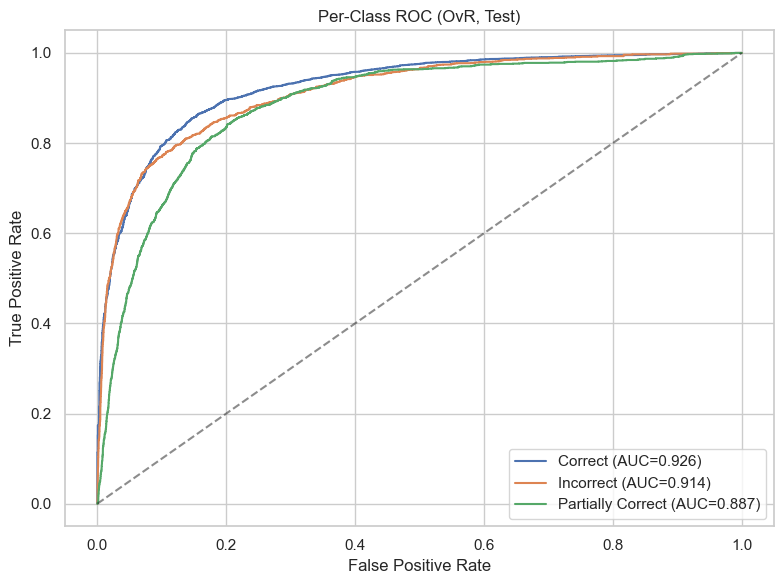

In [18]:
# ============================================================
# CELL 18: ROC Curves (One-vs-Rest)
# ============================================================
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

y_bin = label_binarize(test_true, classes=list(range(NUM_LABELS)))
fig, ax = plt.subplots(figsize=(8, 6))
for i, lbl in enumerate(LABELS):
    if y_bin[:, i].sum() == 0: continue
    fpr, tpr, _ = roc_curve(y_bin[:, i], test_probs[:, i])
    ax.plot(fpr, tpr, label=f"{lbl} (AUC={auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("Per-Class ROC (OvR, Test)"); ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_curves.png", dpi=300, bbox_inches="tight")
plt.show()

Expected Calibration Error (ECE): 0.1644


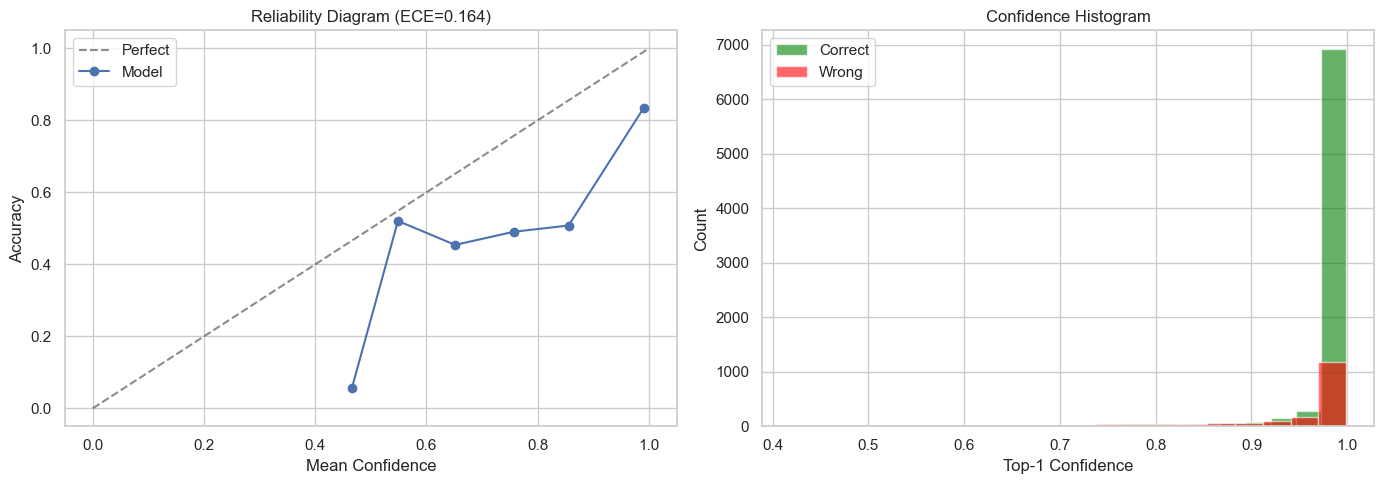

In [19]:
# ============================================================
# CELL 19: Calibration Analysis (ECE + Reliability Diagram)
# ============================================================
confidences = test_probs.max(axis=1)
correct = (test_preds == test_true).astype(int)
n_bins, edges = 10, np.linspace(0, 1, 11)
ece = 0.0
pts = []
for i in range(n_bins):
    m = (confidences >= edges[i]) & (confidences < edges[i+1])
    if m.sum() == 0: continue
    mc, ma = confidences[m].mean(), correct[m].mean()
    ece += m.sum() / len(confidences) * abs(mc - ma)
    pts.append(((edges[i]+edges[i+1])/2, mc, ma))

print(f"Expected Calibration Error (ECE): {ece:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
if pts:
    _, cs, acs = zip(*pts)
    axes[0].plot([0,1], [0,1], "k--", alpha=0.5, label="Perfect")
    axes[0].plot(cs, acs, "o-", label="Model")
    axes[0].set_xlabel("Mean Confidence"); axes[0].set_ylabel("Accuracy")
    axes[0].set_title(f"Reliability Diagram (ECE={ece:.3f})"); axes[0].legend()

axes[1].hist(confidences[correct==1], bins=20, alpha=0.6, color="green", label="Correct")
axes[1].hist(confidences[correct==0], bins=20, alpha=0.6, color="red",   label="Wrong")
axes[1].set_xlabel("Top-1 Confidence"); axes[1].set_ylabel("Count")
axes[1].set_title("Confidence Histogram"); axes[1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "calibration.png", dpi=300, bbox_inches="tight")
plt.show()

  language  samples  accuracy  macro_f1  weighted_f1  cohen_kappa
0       EN     1614    0.8017    0.7382       0.7995       0.6201
1       HI     1626    0.8180    0.7357       0.8173       0.6358
2    HI-EN     1620    0.7827    0.7542       0.7822       0.6423
3       NE     1626    0.7940    0.7377       0.7932       0.6387
4       TA     1620    0.8247    0.7511       0.8220       0.6659
5       TE     1614    0.7993    0.7220       0.7965       0.6247


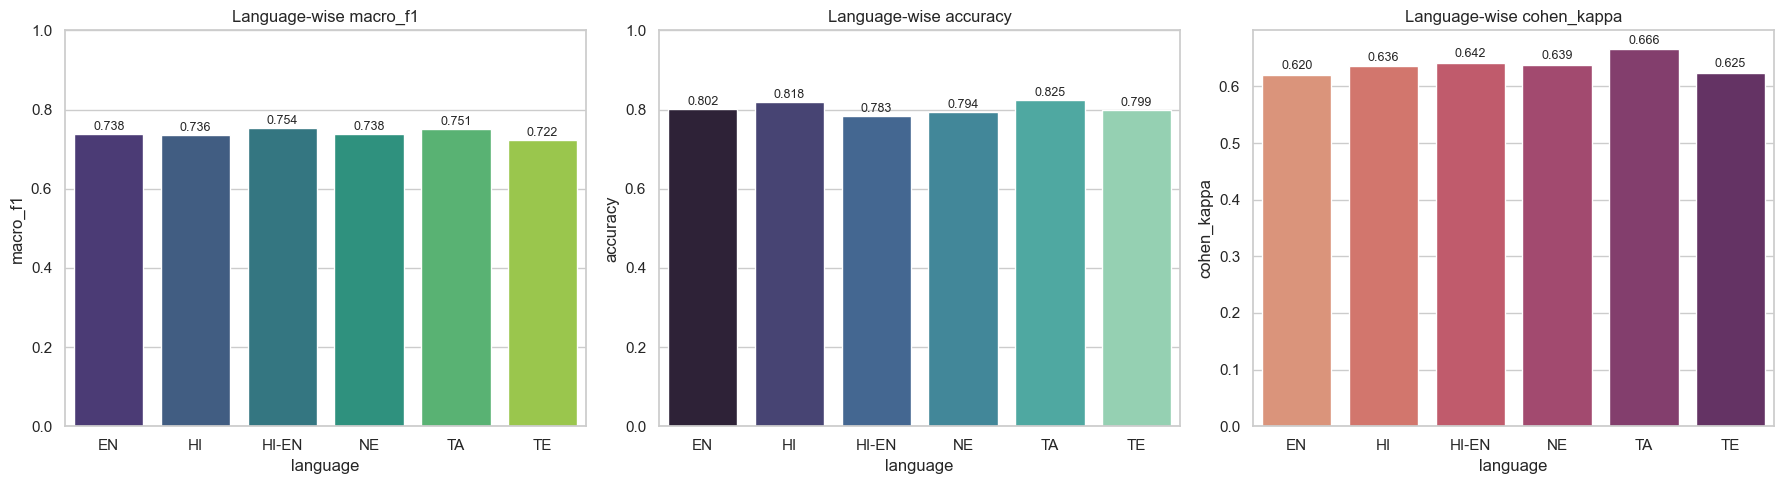

In [20]:
# ============================================================
# CELL 20: Language-Wise Metrics
# ============================================================
def grouped_metrics(df, group_col):
    rows = []
    for g in sorted(df[group_col].dropna().unique()):
        mask = df[group_col].to_numpy() == g
        yt, yp = test_true[mask], test_preds[mask]
        if len(yt) == 0: continue
        rows.append({
            group_col: g, "samples": int(mask.sum()),
            "accuracy": accuracy_score(yt, yp),
            "macro_f1": f1_score(yt, yp, labels=list(range(NUM_LABELS)),
                                 average="macro", zero_division=0),
            "weighted_f1": f1_score(yt, yp, labels=list(range(NUM_LABELS)),
                                    average="weighted", zero_division=0),
            "cohen_kappa": cohen_kappa_score(yt, yp),
        })
    return pd.DataFrame(rows)

lang_df = grouped_metrics(test_df, "language")
print(lang_df.round(4))
lang_df.to_csv(OUTPUT_DIR / "language_wise_results.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col, cmap in zip(axes, ["macro_f1", "accuracy", "cohen_kappa"],
                        ["viridis", "mako", "flare"]):
    sns.barplot(data=lang_df, x="language", y=col, ax=ax, palette=cmap)
    ax.set_title(f"Language-wise {col}")
    if col != "cohen_kappa": ax.set_ylim(0, 1)
    for i, v in enumerate(lang_df[col]):
        ax.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "language_wise.png", dpi=300, bbox_inches="tight")
plt.show()

In [21]:
# ============================================================
# CELL 21: Domain / Difficulty / Fact-Type Wise Metrics
# ============================================================
for col in ["domain_ref", "difficulty_ref", "fact_type_resp"]:
    if col in test_df.columns:
        df_g = grouped_metrics(test_df, col)
        print(f"\n{col}:")
        print(df_g.round(4))
        df_g.to_csv(OUTPUT_DIR / f"{col}_wise_results.csv", index=False)

In [22]:
# ============================================================
# CELL 22: Save Predictions, Metrics, and Splits
# ============================================================
pred_df = test_df[[
    "response_id", "question_id", "language", "model_name",
    "correctness_label", "question", "ground_truth", "response",
]].copy()
pred_df["predicted_label"] = label_encoder.inverse_transform(test_preds)
pred_df["confidence"] = test_probs.max(axis=1)
pred_df["correct_prediction"] = (
    pred_df["correctness_label"] == pred_df["predicted_label"]
)
for i, lbl in enumerate(LABELS):
    pred_df[f"prob_{lbl}"] = test_probs[:, i]

pred_df.to_csv(OUTPUT_DIR / "test_predictions_full.csv", index=False)
pred_df[~pred_df["correct_prediction"]].to_csv(
    OUTPUT_DIR / "test_errors.csv", index=False
)

metrics_output = {
    "model": MODEL_NAME, "task": "Four-class correctness classification",
    "train_rows": len(train_df), "dev_rows": len(dev_df), "test_rows": len(test_df),
    "labels": LABELS, "seed": SEED,
    "test_metrics": {
        "accuracy": float(test_acc),
        "macro_f1": float(test_mf1),
        "weighted_f1": float(test_wf1),
        "cohen_kappa": float(test_kap),
        "mcc": float(test_mcc),
        "roc_auc_macro": float(test_auc) if not np.isnan(test_auc) else None,
        "log_loss": float(test_ll) if not np.isnan(test_ll) else None,
        "top2_accuracy": float(test_top2) if not np.isnan(test_top2) else None,
        "ece": float(ece),
    },
    "per_class": per_class.to_dict(orient="records"),
}
with open(OUTPUT_DIR / "test_metrics_full.json", "w", encoding="utf-8") as f:
    json.dump(metrics_output, f, indent=4)

train_df.to_csv(OUTPUT_DIR / "train_split.csv", index=False)
dev_df.to_csv(OUTPUT_DIR / "dev_split.csv", index=False)
test_df.to_csv(OUTPUT_DIR / "test_split.csv", index=False)

print("\nAll artifacts saved to:", OUTPUT_DIR)


All artifacts saved to: C:\Users\CH.SC.U4CSE23160\Neural Project\IndicHallbench-Hallucinations-Benchmark\results\muril_base_full_dataset


Font chain: ['DejaVu Sans', 'Nirmala UI']
font                 DejaVu Sans  Nirmala UI
script                                      
Bengali                    False        True
Devanagari (Hindi)         False        True
Devanagari (Nepali)        False        True
Gujarati                   False        True
Gurmukhi                   False        True
Kannada                    False        True
Latin                       True        True
Malayalam                  False        True
Tamil                      False        True
Telugu                     False        True


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 9572.45it/s]



Test: 3051 true-positive hallucinations, 602 false alarms


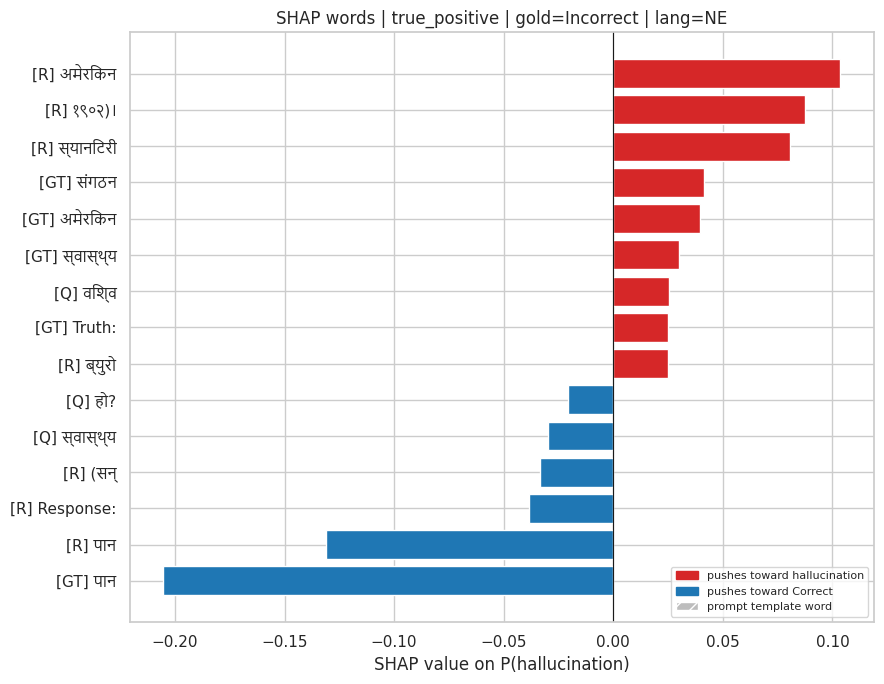

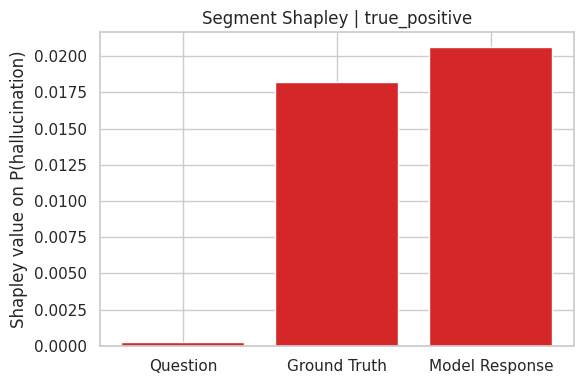

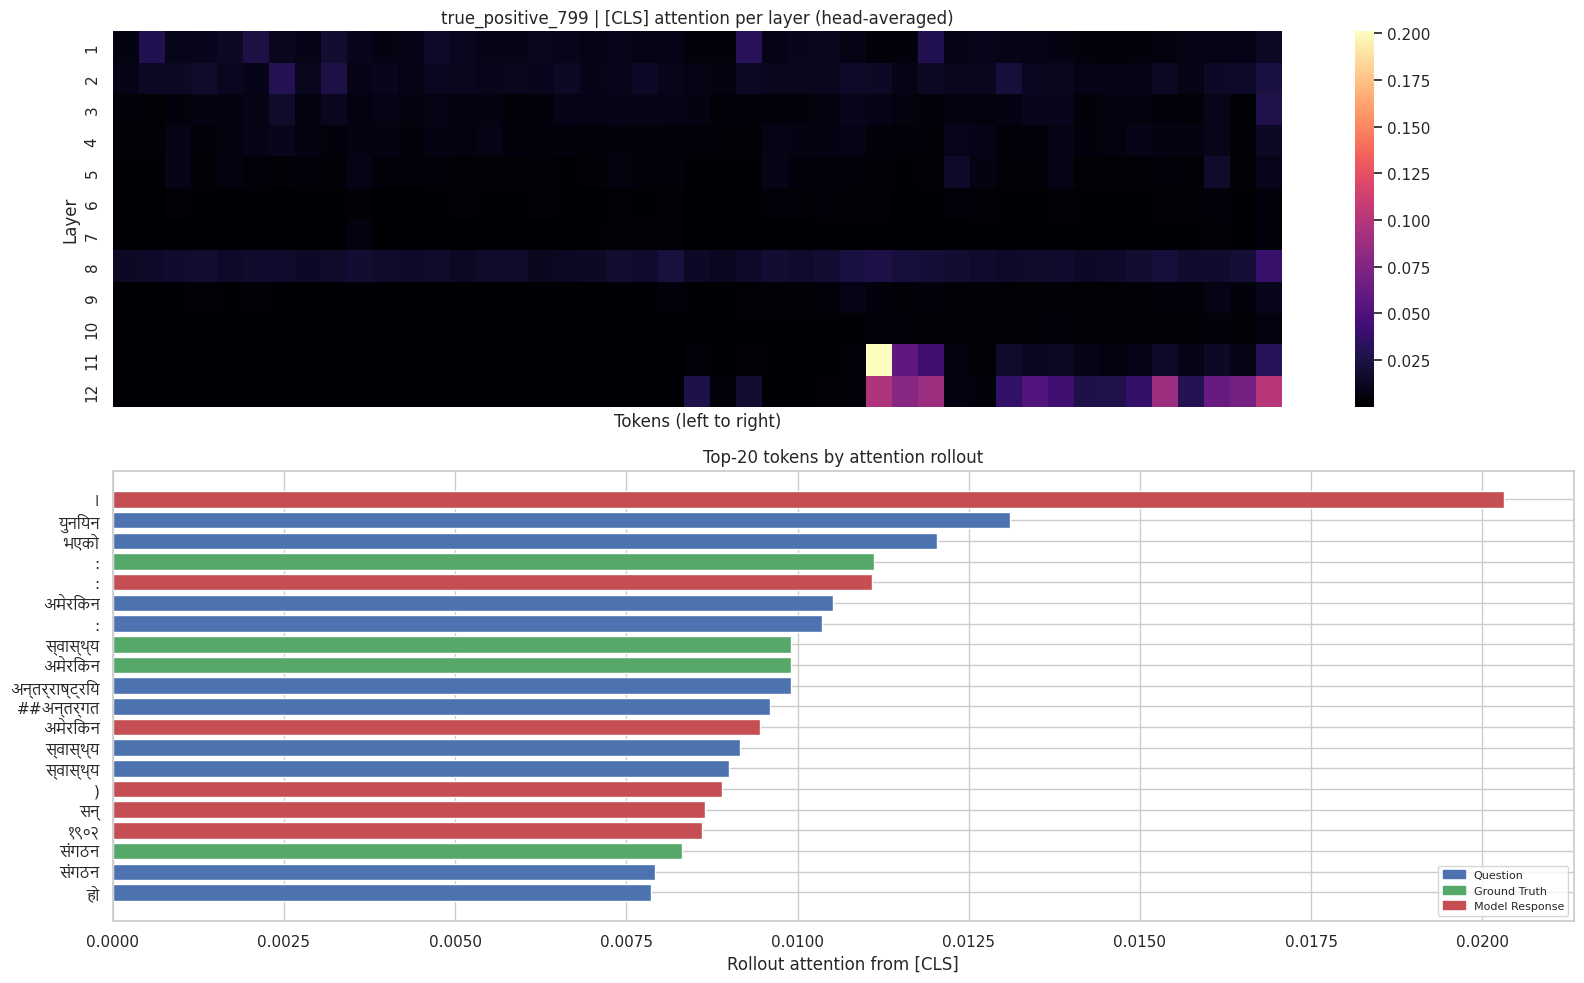

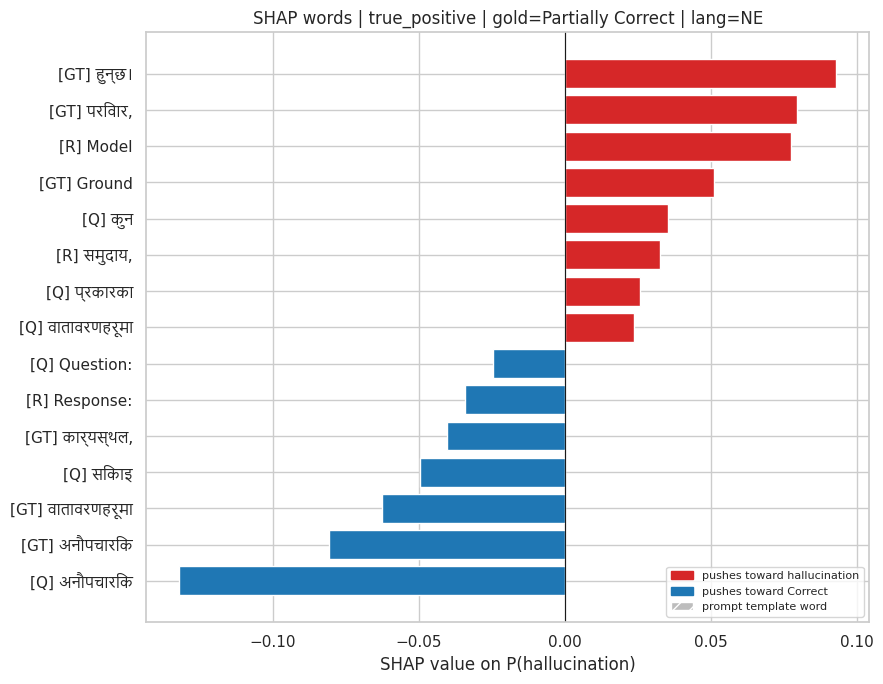

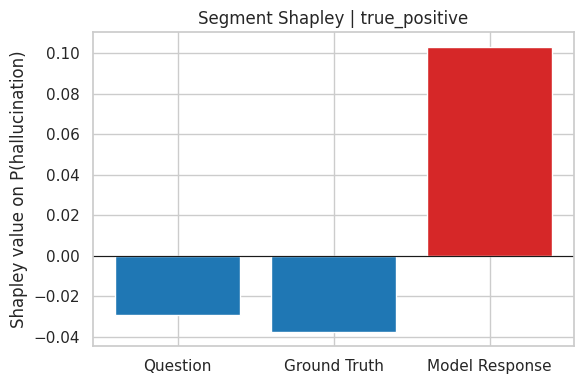

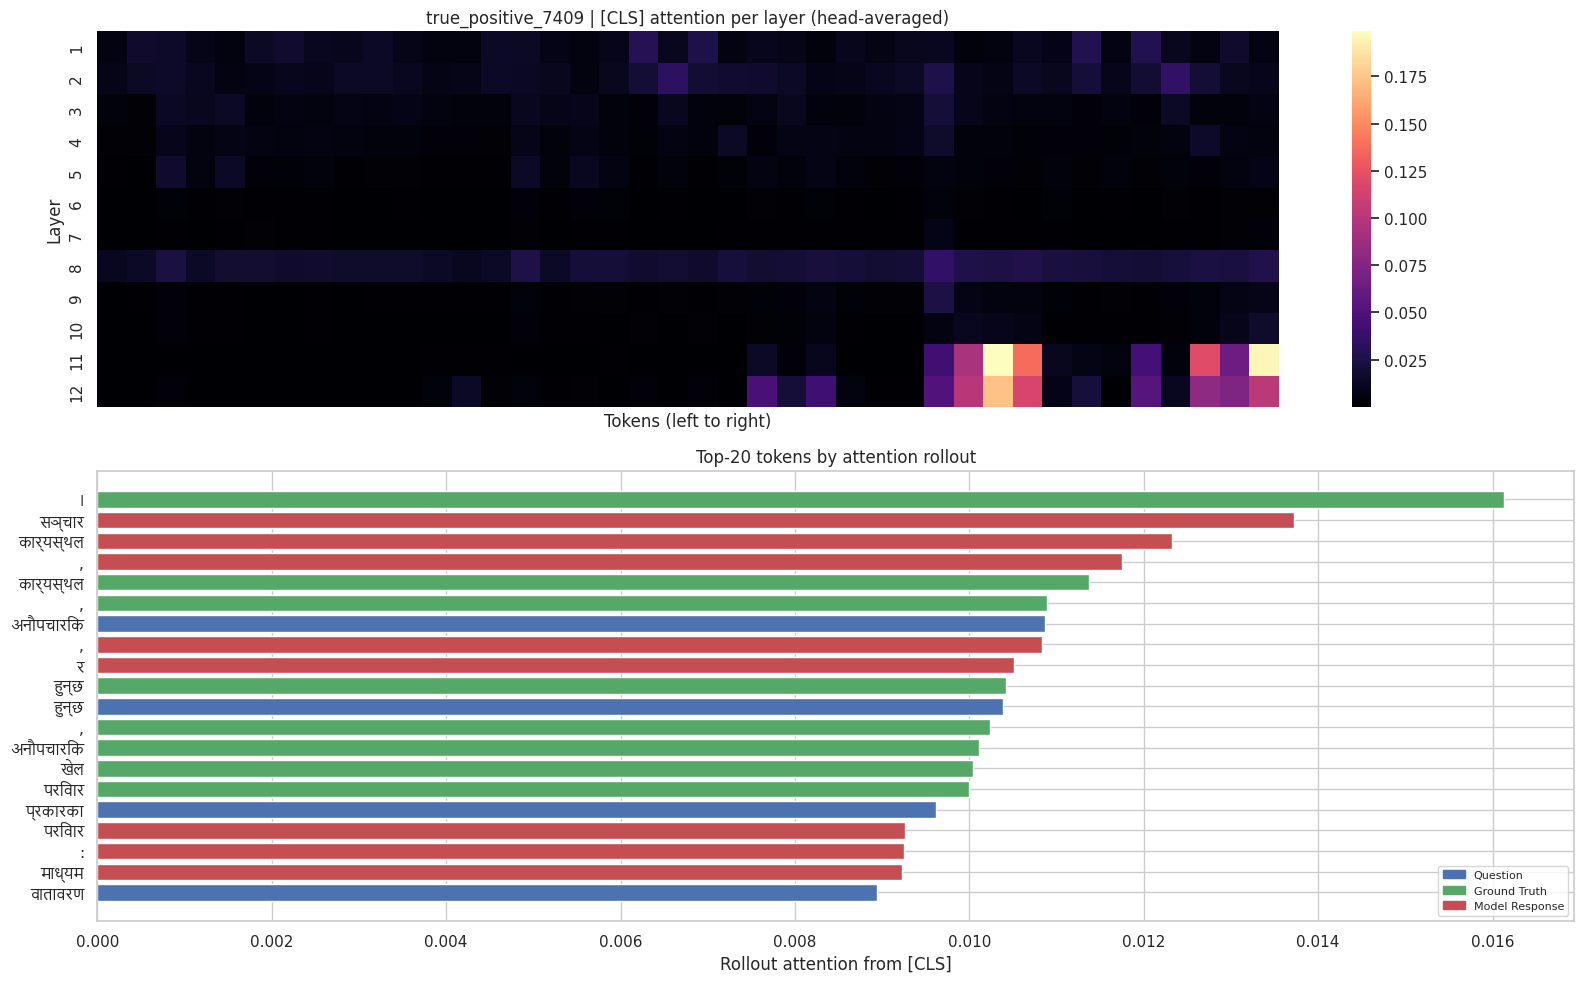

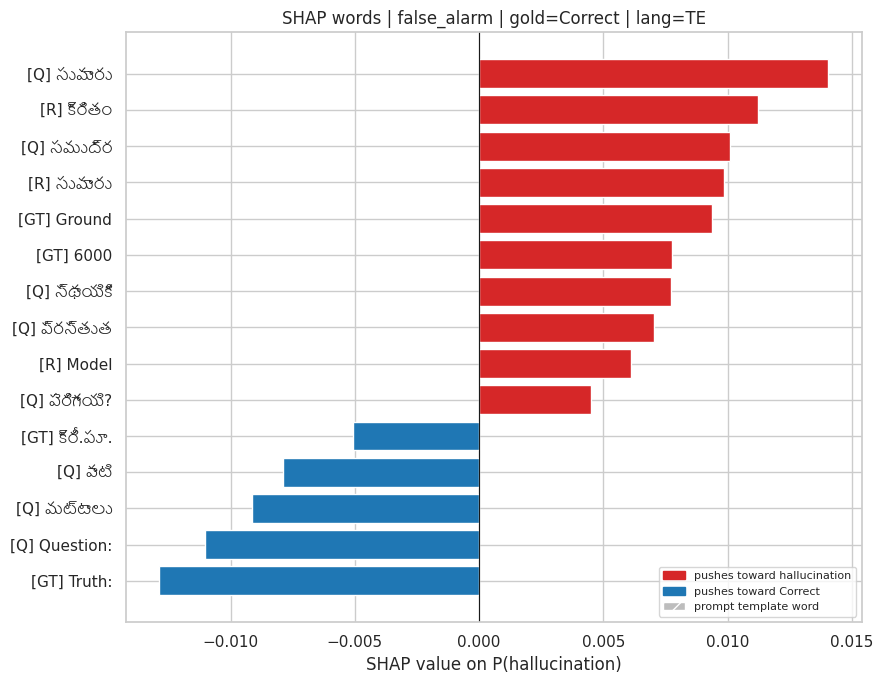

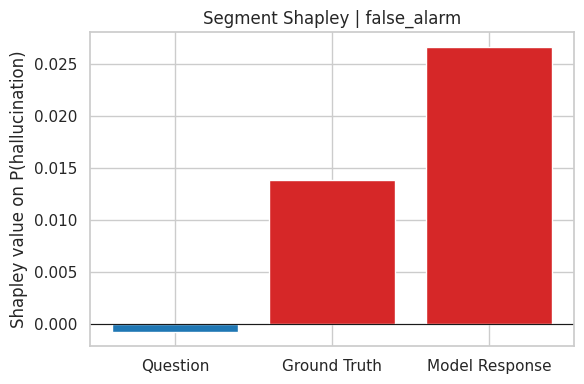

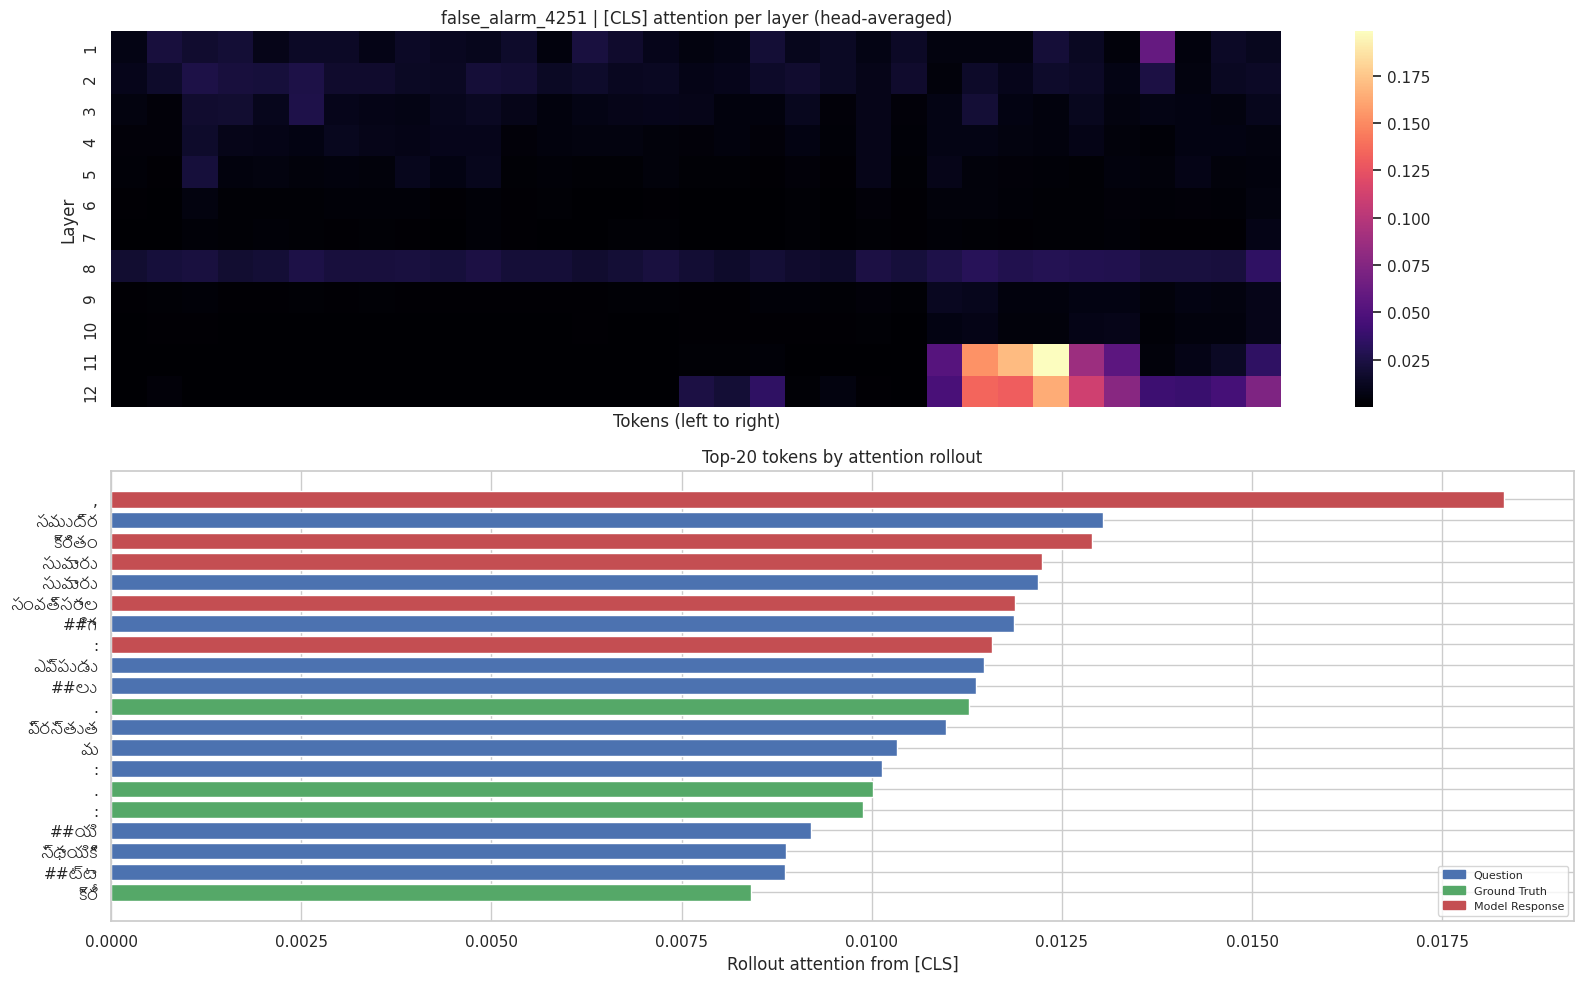

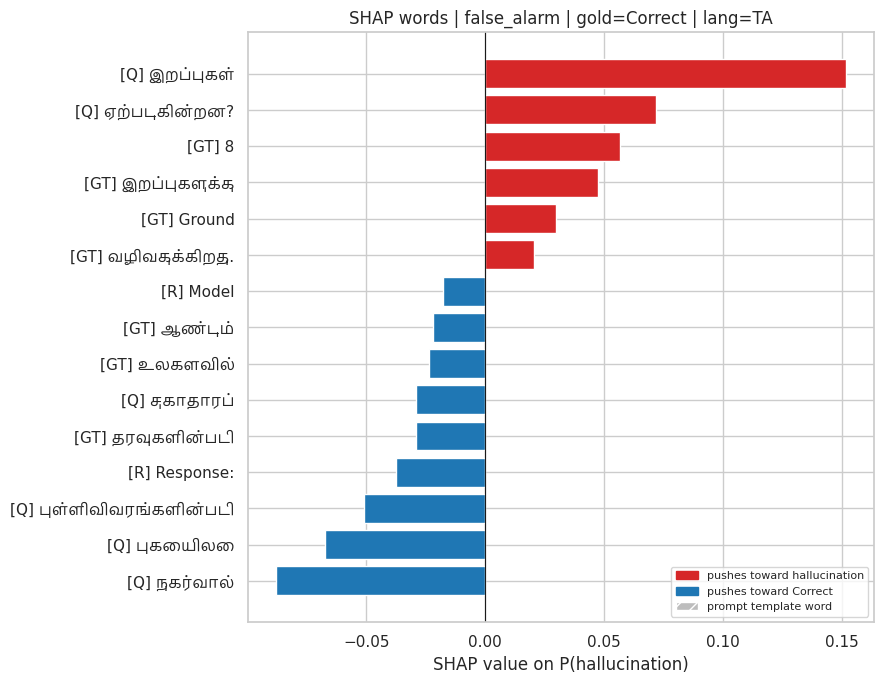

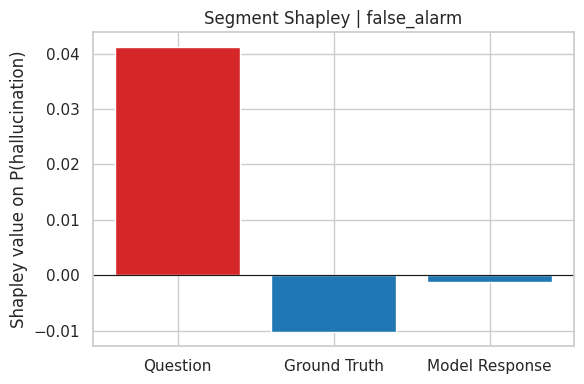

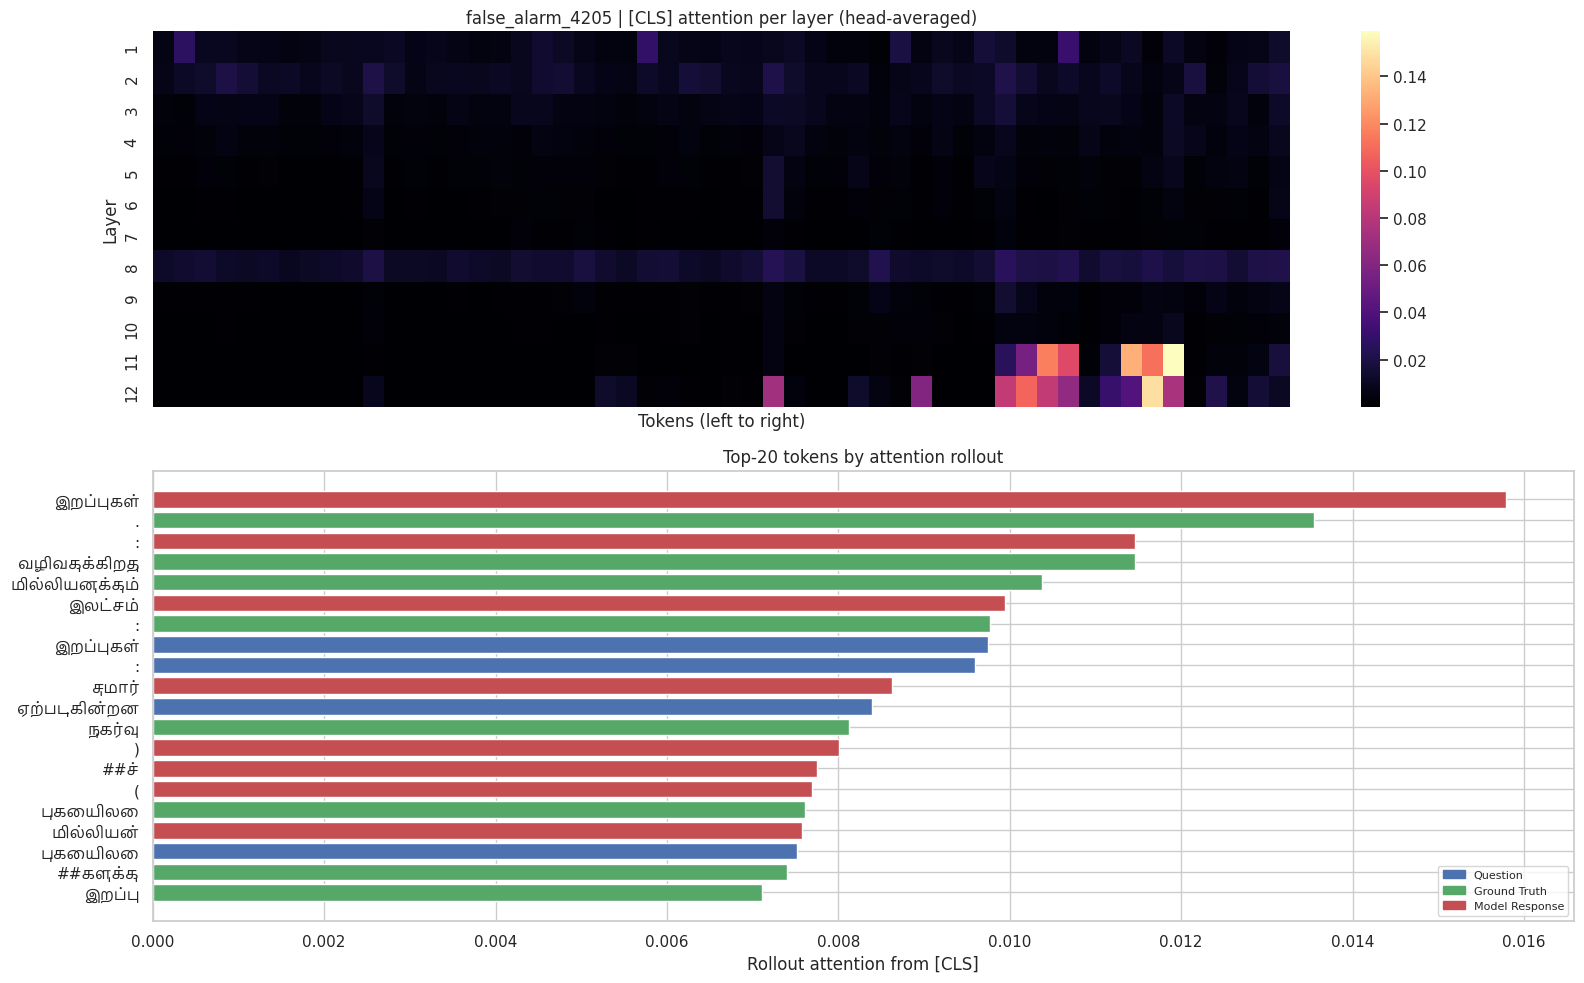

           example              gold language  P_hallu  shap_additivity_gap  phi_question  phi_ground_truth  phi_response
 true_positive_799         Incorrect       NE   0.9988                  0.0        0.0002            0.0182        0.0206
true_positive_7409 Partially Correct       NE   0.9961                  0.0       -0.0294           -0.0375        0.1032
  false_alarm_4251           Correct       TE   0.9995                  0.0       -0.0008            0.0138        0.0267
  false_alarm_4205           Correct       TA   0.9897                  0.0        0.0413           -0.0102       -0.0012

Per-language segment importance (SHAP vs attention):
language  n  SHAP_question  SHAP_ground_truth  SHAP_response  Attn_question  Attn_ground_truth  Attn_response  mean_shap_gap  mean_P_hallu
      EN 25          0.092              0.401          0.506          0.386              0.301          0.313            0.0         0.213
      HI 25          0.086              0.396          0.5

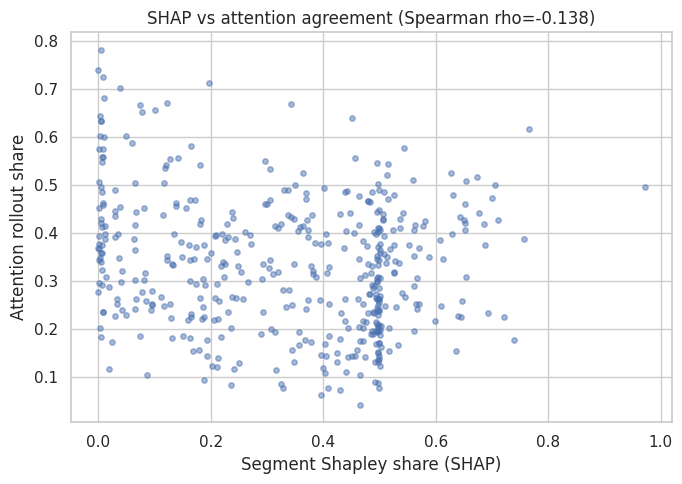

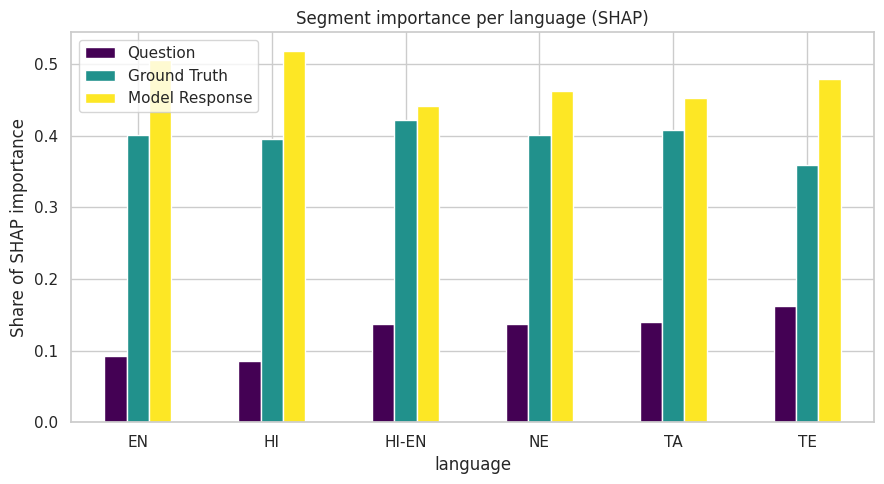


Faithfulness (deletion test on predicted-hallucination examples):
 delete_fraction  n  mean_drop_SHAP  mean_drop_random  wilcoxon_p(one-sided)
             0.1 49          0.2563            0.0316                 0.0009
             0.2 49          0.2402            0.0247                 0.0092
             0.3 49          0.1394            0.0358                 0.0342


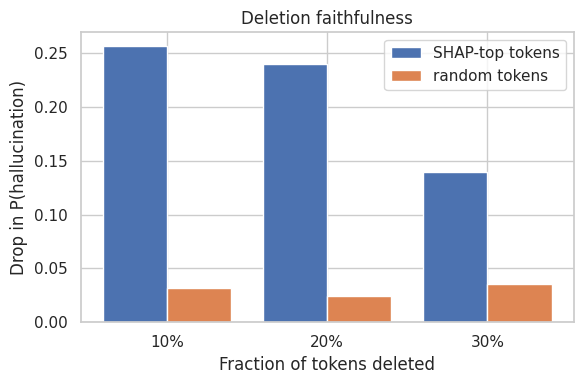

PartitionExplainer explainer: 61it [00:23,  1.56it/s]                        



Global top tokens (dev sample):
                  mean_shap  mean_abs_shap  n
token                                        
अरब                 -0.2228         0.2267  4
स्तर                -0.1236         0.1236  3
karl                -0.1155         0.1175  3
பெருங்கடல்          -0.1001         0.1001  4
world               -0.0928         0.0955  4
massachusetts       -0.0559         0.0950  3
రెండు               -0.0893         0.0893  3
प्राचीन             -0.0867         0.0867  3
अफ्रीका             -0.0806         0.0806  3
दूसरा               -0.0791         0.0791  3
अध्ययन              -0.0077         0.0776  3
காஃப்               -0.0713         0.0713  3
pehla               -0.0712         0.0712  3
lagu                -0.0627         0.0630  3
எந்த                -0.0586         0.0586  4
संयुक्त             -0.0509         0.0585  3
पोलियो              -0.0381         0.0578  3
हार्वे              -0.0460         0.0568  3
நாடுகளிலிருந்து     -0.0210         0.0501  3
ज

PartitionExplainer explainer: 61it [00:22,  1.54it/s]                        


Step,Training Loss


KeyboardInterrupt: 

In [28]:
# ============================================================
# CELL 23 (v3): COMPLETE EXPLAINABILITY ANALYSIS  (run after Cell 22)
#
#   0. Fonts: Indic-script rendering + glyph-coverage check
#   1. Shared helpers (prediction, SHAP target, additivity check)
#   2. Per-example SHAP word explanations (true positive, false alarm)
#   3. Exact segment-level Shapley (Question / Ground Truth / Response)
#   4. Attention visualization + attention rollout
#   5. Per-example explanation figures
#   6. Per-language explanations + SHAP vs attention agreement
#   7. Faithfulness: SHAP-guided deletion vs matched random deletion
#   8. Global SHAP over a dev sample
#   9. SHAP-guided iterative refinement vs matched random-cue control
#  10. Final test statistics: McNemar, bootstrap CIs, per-language F1
#  11. LaTeX export of every table
#
# v3 change: the training batch is built by keep_all_fields_collator,
# which keeps sample_weight. The earlier tokenizer-based collator
# dropped it, causing KeyError: 'sample_weight'.
#
# Uses variables from Cells 1-22: model, tokenizer, train_df, dev_df,
# test_df, train_dataset, LABELS, DEVICE, OUTPUT_DIR, MAX_LENGTH,
# TRAIN_BATCH_SIZE, EVAL_BATCH_SIZE, WEIGHT_DECAY, class_weights, SEED.
# Install once:  pip install shap scipy
#
# "Hallucination" = any non-Correct label (Incorrect or Partially Correct).
# SHAP target: f(x) = P(hallucination | x) = 1 - P(Correct | x).
# ============================================================
import copy
import re
import string
from collections import defaultdict
from itertools import combinations
from math import factorial

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import shap
from scipy.stats import chi2, spearmanr, wilcoxon
from matplotlib import font_manager as fm
from matplotlib.font_manager import FontProperties
from matplotlib.ft2font import FT2Font
from transformers import (AutoModelForSequenceClassification, Trainer,
                          TrainingArguments)
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score)

sns.set_theme(style="whitegrid")
EXPL_DIR = OUTPUT_DIR / "explainability"
EXPL_DIR.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(SEED)

IDX_CORRECT = LABELS.index("Correct")
SEGMENTS = ["question", "ground_truth", "response"]
SEG_HEADERS = {"question": "Question", "ground_truth": "Ground Truth",
               "response": "Model Response"}
SEG_NAMES = ["Question", "Ground Truth", "Model Response"]
SEG_TAG = {0: "Q", 1: "GT", 2: "R"}
TEMPLATE_WORDS = {"question", "ground", "truth", "model", "response"}

# Experiment settings
N_SHAP_DEV     = 60      # dev examples explained per refinement round
SHAP_MAX_EVALS = 300     # perturbation budget per example
PER_LANG       = 25      # test examples per language for explanation analysis
N_FAITH        = 80      # predicted-hallucination examples for faithfulness
FRACS          = [0.1, 0.2, 0.3]
N_RANDOM       = 5       # random deletions averaged per example
TOP_CUES       = 30
CUE_BOOST      = 1.0
ITER_ROUNDS    = 3
ROUND_EPOCHS   = 2
ROUND_LR       = 1e-5
N_BOOT         = 1000


# ------------------------------------------------------------
# 0. FONTS: Indic scripts must render (no empty boxes)
# ------------------------------------------------------------
INDIC_FONT_CANDIDATES = [
    "Nirmala UI",             # ships with Windows; covers all Indic scripts below
    "Noto Sans Devanagari", "Noto Sans Tamil", "Noto Sans Telugu",
    "Noto Sans Kannada", "Noto Sans Malayalam", "Noto Sans Bengali",
    "Noto Sans Gujarati", "Noto Sans Gurmukhi", "Noto Sans Oriya",
    "Noto Sans Sinhala",
]
_installed = {f.name for f in fm.fontManager.ttflist}
FONT_CHAIN = ["DejaVu Sans"] + [f for f in INDIC_FONT_CANDIDATES if f in _installed]
plt.rcParams["font.family"] = FONT_CHAIN
plt.rcParams["pdf.fonttype"] = 42        # editable text in PDF/EPS for journals
plt.rcParams["ps.fonttype"] = 42

SCRIPT_SAMPLES = {
    "Latin": "hello", "Devanagari (Hindi)": "हिन्दी", "Devanagari (Nepali)": "नेपाली",
    "Tamil": "தமிழ்", "Telugu": "తెలుగు", "Kannada": "ಕನ್ನಡ",
    "Malayalam": "മലയാളം", "Bengali": "বাংলা", "Gujarati": "ગુજરાતી",
    "Gurmukhi": "ਪੰਜਾਬੀ",
}


def font_coverage_table():
    rows = []
    for name in FONT_CHAIN:
        try:
            path = fm.findfont(FontProperties(family=name), fallback_to_default=False)
        except Exception:
            continue
        ft = FT2Font(path)
        for script, sample in SCRIPT_SAMPLES.items():
            ok = all(ft.get_char_index(ord(ch)) != 0 for ch in sample if not ch.isspace())
            rows.append({"font": name, "script": script, "covered": ok})
    return pd.DataFrame(rows)


cov = font_coverage_table()
print("Font chain:", FONT_CHAIN)
if not cov.empty:
    print(cov.pivot(index="script", columns="font", values="covered").to_string())
uncovered = [s for s in SCRIPT_SAMPLES
             if not cov[(cov.script == s) & cov.covered].shape[0]]
if uncovered:
    print("WARNING: no installed font covers:", uncovered,
          "- install Noto Sans for these scripts to avoid boxes in figures.")
cov.to_csv(EXPL_DIR / "font_coverage.csv", index=False)


# ------------------------------------------------------------
# 1. Shared helpers
# ------------------------------------------------------------
@torch.no_grad()
def predict_proba(texts, mdl=None, batch_size=EVAL_BATCH_SIZE):
    if mdl is None:
        mdl = model
    mdl.eval()
    out = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(list(texts[i:i + batch_size]), truncation=True,
                        padding=True, max_length=MAX_LENGTH,
                        return_tensors="pt").to(DEVICE)
        with torch.autocast(device_type="cuda", dtype=torch.float16,
                            enabled=(DEVICE == "cuda")):
            logits = mdl(**enc).logits
        out.append(torch.softmax(logits.float(), dim=-1).cpu().numpy())
    return np.vstack(out)


def hallu_score(texts, mdl=None):
    """SHAP target: P(hallucination) = 1 - P(Correct)."""
    return 1.0 - predict_proba(texts, mdl)[:, IDX_CORRECT]


def token_norm(tok):
    return tok.strip(string.punctuation + "।॥“”‘’–—…").lower()


def token_seg_labels(text, toks):
    """Segment index (0=Q, 1=GT, 2=R) for each whitespace token, by position."""
    g = text.find("Ground Truth:")
    r = text.find("Model Response:")
    pos, out = 0, []
    for t in toks:
        j = text.find(t, pos) if t else -1
        if j >= 0:
            pos = j + len(t)
        else:
            j = pos
        out.append(2 if j >= r else (1 if j >= g else 0))
    return out


# ------------------------------------------------------------
# 2. Word-level SHAP
# ------------------------------------------------------------
def shap_explain(texts, mdl=None, max_evals=SHAP_MAX_EVALS):
    masker = shap.maskers.Text(r"\s+")          # whitespace tokens (Indic-safe)
    f = lambda x: hallu_score(list(x), mdl)
    explainer = shap.Explainer(f, masker, algorithm="partition")
    return explainer(list(texts), max_evals=max_evals, batch_size=EVAL_BATCH_SIZE)


def plot_example_shap(sv, text, title, top_k=15, path=None):
    """Top-k words: red pushes toward hallucination, blue toward Correct,
    grey hatched = prompt template words (not model content)."""
    toks = np.asarray(sv.data)
    vals = np.asarray(sv.values)
    segs = token_seg_labels(text, toks)
    content = [i for i, t in enumerate(toks) if t.strip()]
    order = sorted(content, key=lambda i: -abs(vals[i]))[:top_k]
    order = sorted(order, key=lambda i: vals[i])

    labels, colors, hatches = [], [], []
    for i in order:
        labels.append(f"[{SEG_TAG[segs[i]]}] {toks[i].strip()[:28]}")
        template = token_norm(toks[i]) in TEMPLATE_WORDS
        colors.append("#bdbdbd" if template else
                      ("#d62728" if vals[i] > 0 else "#1f77b4"))
        hatches.append("//" if template else "")

    fig, ax = plt.subplots(figsize=(9, 7))
    bars = ax.barh(range(len(order)), [vals[i] for i in order], color=colors)
    for b, h in zip(bars, hatches):
        b.set_hatch(h)
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(labels)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_xlabel("SHAP value on P(hallucination)")
    ax.set_title(title)
    ax.legend(handles=[
        mpatches.Patch(color="#d62728", label="pushes toward hallucination"),
        mpatches.Patch(color="#1f77b4", label="pushes toward Correct"),
        mpatches.Patch(facecolor="#bdbdbd", hatch="//", label="prompt template word"),
    ], loc="lower right", fontsize=8)
    plt.tight_layout()
    if path:
        plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()


def shap_additivity_gap(sv, text, mdl=None):
    """|base + sum(SHAP) - f(x)|: how faithfully SHAP reconstructs the output."""
    f_x = float(hallu_score([text], mdl)[0])
    return abs(float(np.sum(sv.values)) + float(np.mean(sv.base_values)) - f_x), f_x


def aggregate_token_shap(sv_list, wrong_flags):
    rows = []
    for j, e in enumerate(sv_list):
        for tok, v in zip(np.asarray(e.data), np.asarray(e.values)):
            t = token_norm(tok)
            if len(t) >= 3 and re.search(r"\w", t) and t not in TEMPLATE_WORDS:
                rows.append((t, float(v), bool(wrong_flags[j]), j))
    return pd.DataFrame(rows, columns=["token", "shap", "wrong", "example"])


def summarize_tokens(df_tok, min_count=3, top_k=20):
    g = df_tok.groupby("token").agg(
        mean_shap=("shap", "mean"),
        mean_abs_shap=("shap", lambda s: s.abs().mean()),
        n=("shap", "size"),
    )
    return g[g.n >= min_count].sort_values("mean_abs_shap", ascending=False).head(top_k)


# ------------------------------------------------------------
# 3. Exact segment-level Shapley (3 players, 8 coalitions)
# ------------------------------------------------------------
def seg_text(row, keep):
    lines = []
    for k in SEGMENTS:
        val = str(row[k]) if k in keep else ""
        lines.append(f"{SEG_HEADERS[k]}: {val}")
    return "\n".join(lines)


def exact_segment_shapley(row, mdl=None):
    n = len(SEGMENTS)
    cache = {}

    def v(S):
        key = frozenset(S)
        if key not in cache:
            cache[key] = float(hallu_score([seg_text(row, key)], mdl)[0])
        return cache[key]

    phi = {}
    for p in SEGMENTS:
        others = [q for q in SEGMENTS if q != p]
        total = 0.0
        for k in range(n):
            w = factorial(k) * factorial(n - k - 1) / factorial(n)
            for S in combinations(others, k):
                total += w * (v(set(S) | {p}) - v(set(S)))
        phi[p] = total
    base, full = v(set()), v(set(SEGMENTS))
    assert abs(sum(phi.values()) - (full - base)) < 1e-6, "Shapley efficiency violated"
    return phi, base, full


def shapley_share(phi):
    mag = {k: abs(phi[k]) for k in SEGMENTS}
    tot = sum(mag.values()) or 1.0
    return [mag[k] / tot for k in SEGMENTS]


def plot_segment_shapley(phi, title, path=None):
    names = [SEG_HEADERS[k] for k in SEGMENTS]
    vals = [phi[k] for k in SEGMENTS]
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(names, vals, color=["#d62728" if v > 0 else "#1f77b4" for v in vals])
    ax.axhline(0, color="k", lw=0.8)
    ax.set_ylabel("Shapley value on P(hallucination)")
    ax.set_title(title)
    plt.tight_layout()
    if path:
        plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()


# ------------------------------------------------------------
# 4. Attention visualization + rollout
# ------------------------------------------------------------
att_model = AutoModelForSequenceClassification.from_pretrained(
    OUTPUT_DIR / "best_model", attn_implementation="eager"
).to(DEVICE).eval()


@torch.no_grad()
def get_attention(text, mdl=None):
    mdl = att_model if mdl is None else mdl
    enc = tokenizer(text, truncation=True, max_length=MAX_LENGTH,
                    return_offsets_mapping=True, return_tensors="pt")
    offsets = enc.pop("offset_mapping")[0].numpy()
    enc = enc.to(DEVICE)
    out = mdl(**enc, output_attentions=True)
    A = torch.stack(out.attentions)[:, 0].float().cpu().numpy()     # (L,H,T,T)
    ids = enc["input_ids"][0].cpu().numpy()
    keep = enc["attention_mask"][0].cpu().numpy().astype(bool)
    tokens = tokenizer.convert_ids_to_tokens(ids[keep])
    A = A[:, :, keep][:, :, :, keep]
    return tokens, offsets[keep], A


def attention_rollout(A):
    """Abnar & Zuidema (2020). Returns [CLS] influence on every token."""
    M = A.mean(axis=1)
    T = M.shape[-1]
    R = np.eye(T)
    for layer in M:
        layer = layer + np.eye(T)
        layer = layer / layer.sum(-1, keepdims=True)
        R = layer @ R
    return R[0]


def token_segments(text, offsets):
    g = text.find("Ground Truth:")
    r = text.find("Model Response:")
    starts = offsets[:, 0]
    seg = np.where(starts >= r, 2, np.where(starts >= g, 1, 0))
    special = (offsets[:, 0] == 0) & (offsets[:, 1] == 0)
    return seg, special


def attention_shares(text):
    tokens, offsets, A = get_attention(text)
    rollout = attention_rollout(A)
    seg, special = token_segments(text, offsets)
    real = ~special
    tot = rollout[real].sum()
    return [float(rollout[(seg == s) & real].sum() / tot) for s in range(3)]


def plot_attention(text, title, path=None):
    tokens, offsets, A = get_attention(text)
    rollout = attention_rollout(A)
    seg, special = token_segments(text, offsets)
    real = ~special

    fig, axes = plt.subplots(2, 1, figsize=(16, 10),
                             gridspec_kw={"height_ratios": [1, 1.2]})
    cls_per_layer = A.mean(axis=1)[:, 0, :][:, real]
    sns.heatmap(cls_per_layer, ax=axes[0], cmap="magma", xticklabels=False,
                yticklabels=range(1, A.shape[0] + 1))
    axes[0].set_title(f"{title} | [CLS] attention per layer (head-averaged)")
    axes[0].set_xlabel("Tokens (left to right)")
    axes[0].set_ylabel("Layer")

    idx = np.where(real)[0]
    top = idx[np.argsort(-rollout[idx])][:20]
    top = top[np.argsort(rollout[top])]
    palette = ["#4C72B0", "#55A868", "#C44E52"]
    axes[1].barh(range(len(top)), rollout[top], color=[palette[seg[i]] for i in top])
    axes[1].set_yticks(range(len(top)))
    axes[1].set_yticklabels([tokens[i] for i in top])
    axes[1].set_title("Top-20 tokens by attention rollout")
    axes[1].set_xlabel("Rollout attention from [CLS]")
    axes[1].legend(handles=[mpatches.Patch(color=palette[s], label=SEG_NAMES[s])
                            for s in range(3)], loc="lower right", fontsize=8)
    plt.tight_layout()
    if path:
        plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()


# ------------------------------------------------------------
# 5. Per-example explanations (TP and false alarm) for the paper
# ------------------------------------------------------------
y_test = test_df["label"].to_numpy()
test_texts = test_df["input_text"].tolist()
probs_base_test = predict_proba(test_texts, model)
pred_base_test = probs_base_test.argmax(1)
hall_true = y_test != IDX_CORRECT
hall_pred = pred_base_test != IDX_CORRECT

tp_idx = np.where(hall_true & hall_pred)[0]
fp_idx = np.where(~hall_true & hall_pred)[0]
print(f"\nTest: {len(tp_idx)} true-positive hallucinations, "
      f"{len(fp_idx)} false alarms")

SV_CACHE = {}                # test row index -> SHAP Explanation (reused everywhere)
FIG_EXAMPLES = []
for kind, pool in [("true_positive", tp_idx), ("false_alarm", fp_idx)]:
    for i in RNG.choice(pool, 2, replace=False):
        i = int(i)
        row = test_df.iloc[i]
        tag = f"{kind}_{i}"
        sv = shap_explain([row["input_text"]])[0]
        SV_CACHE[i] = sv
        gap, _ = shap_additivity_gap(sv, row["input_text"])
        plot_example_shap(sv, row["input_text"],
                          f"SHAP words | {kind} | gold={row['correctness_label']} "
                          f"| lang={row['language']}",
                          path=EXPL_DIR / f"shap_words_{tag}.png")
        phi, base_v, full_v = exact_segment_shapley(row)
        plot_segment_shapley(phi, f"Segment Shapley | {kind}",
                             path=EXPL_DIR / f"shap_segments_{tag}.png")
        plot_attention(row["input_text"], tag, path=EXPL_DIR / f"attention_{tag}.png")
        FIG_EXAMPLES.append({"example": tag, "gold": row["correctness_label"],
                             "language": row["language"], "P_hallu": full_v,
                             "shap_additivity_gap": gap,
                             **{f"phi_{k}": phi[k] for k in SEGMENTS}})

pd.DataFrame(FIG_EXAMPLES).round(4).to_csv(EXPL_DIR / "figure_examples.csv", index=False)
print(pd.DataFrame(FIG_EXAMPLES).round(4).to_string(index=False))


# ------------------------------------------------------------
# 6. Per-language explanations + SHAP vs attention agreement
# ------------------------------------------------------------
LANGS = sorted(test_df["language"].dropna().unique())
lang_ids = {}
for L in LANGS:
    ids = np.where(test_df["language"].to_numpy() == L)[0]
    lang_ids[L] = RNG.choice(ids, min(PER_LANG, len(ids)), replace=False)

records = []
for L, ids in lang_ids.items():
    for i in ids:
        i = int(i)
        row = test_df.iloc[i]
        if i not in SV_CACHE:
            SV_CACHE[i] = shap_explain([row["input_text"]])[0]
        sv = SV_CACHE[i]
        gap, p_h = shap_additivity_gap(sv, row["input_text"])
        phi, base_v, full_v = exact_segment_shapley(row)
        records.append({
            "idx": i, "language": L, "gold": row["correctness_label"],
            "P_hallu": p_h, "shap_gap": gap,
            "shap_share": shapley_share(phi),
            "att_share": attention_shares(row["input_text"]),
            "phi": [phi[k] for k in SEGMENTS],
        })
rec_df = pd.DataFrame(records)

lang_rows = []
for L in LANGS:
    sub = rec_df[rec_df.language == L]
    if sub.empty:
        continue
    sh = np.mean(np.stack(sub.shap_share.values), axis=0)
    at = np.mean(np.stack(sub.att_share.values), axis=0)
    lang_rows.append({
        "language": L, "n": len(sub),
        "SHAP_question": sh[0], "SHAP_ground_truth": sh[1], "SHAP_response": sh[2],
        "Attn_question": at[0], "Attn_ground_truth": at[1], "Attn_response": at[2],
        "mean_shap_gap": sub.shap_gap.mean(), "mean_P_hallu": sub.P_hallu.mean(),
    })
lang_expl = pd.DataFrame(lang_rows)
print("\nPer-language segment importance (SHAP vs attention):")
print(lang_expl.round(3).to_string(index=False))
lang_expl.to_csv(EXPL_DIR / "per_language_segment_importance.csv", index=False)

for L in LANGS:
    ids = lang_ids[L]
    svs = [SV_CACHE[int(i)] for i in ids]
    wrong = [pred_base_test[int(i)] != y_test[int(i)] for i in ids]
    summarize_tokens(aggregate_token_shap(svs, wrong), top_k=10).assign(language=L)\
        .to_csv(EXPL_DIR / f"top_tokens_{L}.csv")

# Agreement: SHAP segment shares vs rollout attention shares (pooled)
x_all = np.concatenate([np.array(s) for s in rec_df.shap_share])
y_all = np.concatenate([np.array(a) for a in rec_df.att_share])
rho_all, p_all = spearmanr(x_all, y_all)
agree_rows = [{"scope": "all segments pooled", "spearman_rho": rho_all, "p_value": p_all}]
for s, name in enumerate(SEG_NAMES):
    xs = np.array([sh[s] for sh in rec_df.shap_share])
    ys = np.array([at[s] for at in rec_df.att_share])
    r, p = spearmanr(xs, ys)
    agree_rows.append({"scope": name, "spearman_rho": r, "p_value": p})
agree_df = pd.DataFrame(agree_rows)
print("\nSHAP vs attention agreement (Spearman):")
print(agree_df.round(4).to_string(index=False))
agree_df.to_csv(EXPL_DIR / "shap_attention_agreement.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(x_all, y_all, alpha=0.5, s=15)
ax.set_xlabel("Segment Shapley share (SHAP)")
ax.set_ylabel("Attention rollout share")
ax.set_title(f"SHAP vs attention agreement (Spearman rho={rho_all:.3f})")
plt.tight_layout()
plt.savefig(EXPL_DIR / "shap_vs_attention.png", dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
lang_plot = lang_expl.set_index("language")[["SHAP_question", "SHAP_ground_truth",
                                             "SHAP_response"]]
lang_plot.columns = SEG_NAMES
lang_plot.plot(kind="bar", ax=ax, rot=0, colormap="viridis")
ax.set_ylabel("Share of SHAP importance")
ax.set_title("Segment importance per language (SHAP)")
plt.tight_layout()
plt.savefig(EXPL_DIR / "per_language_segments.png", dpi=300, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------
# 7. Faithfulness: deleting SHAP-top tokens vs random tokens
# ------------------------------------------------------------
def delete_tokens_text(toks, drop):
    return " ".join(t for i, t in enumerate(toks) if i not in drop and t.strip())


hall_pool = [i for i in SV_CACHE if hallu_score([test_texts[i]], model)[0] > 0.5]
hall_pool = hall_pool[:N_FAITH]
per_example = []
for i in hall_pool:
    sv = SV_CACHE[i]
    toks = np.asarray(sv.data)
    vals = np.asarray(sv.values)
    content = [j for j, t in enumerate(toks) if t.strip()]
    base_p = float(hallu_score([delete_tokens_text(toks, set())], model)[0])
    for frac in FRACS:
        k = max(1, int(round(frac * len(content))))
        top = set(sorted(content, key=lambda j: -vals[j])[:k])
        p_shap = float(hallu_score([delete_tokens_text(toks, top)], model)[0])
        rand_drops = []
        for _ in range(N_RANDOM):
            rs = set(RNG.choice(content, k, replace=False).tolist())
            p_r = float(hallu_score([delete_tokens_text(toks, rs)], model)[0])
            rand_drops.append(base_p - p_r)
        per_example.append({"idx": i, "frac": frac,
                            "shap_drop": base_p - p_shap,
                            "random_drop": float(np.mean(rand_drops))})

faith_df = pd.DataFrame(per_example)
faith_rows = []
for frac in FRACS:
    sub = faith_df[faith_df.frac == frac]
    stat, p = wilcoxon(sub.shap_drop, sub.random_drop, alternative="greater")
    faith_rows.append({"delete_fraction": frac, "n": len(sub),
                       "mean_drop_SHAP": sub.shap_drop.mean(),
                       "mean_drop_random": sub.random_drop.mean(),
                       "wilcoxon_p(one-sided)": p})
faith_summary = pd.DataFrame(faith_rows)
print("\nFaithfulness (deletion test on predicted-hallucination examples):")
print(faith_summary.round(4).to_string(index=False))
faith_summary.to_csv(EXPL_DIR / "faithfulness_deletion.csv", index=False)

fig, ax = plt.subplots(figsize=(6, 4))
x = np.arange(len(FRACS))
ax.bar(x - 0.2, faith_summary.mean_drop_SHAP, 0.4, label="SHAP-top tokens")
ax.bar(x + 0.2, faith_summary.mean_drop_random, 0.4, label="random tokens")
ax.set_xticks(x)
ax.set_xticklabels([f"{int(f*100)}%" for f in FRACS])
ax.set_xlabel("Fraction of tokens deleted")
ax.set_ylabel("Drop in P(hallucination)")
ax.set_title("Deletion faithfulness")
ax.legend()
plt.tight_layout()
plt.savefig(EXPL_DIR / "faithfulness_deletion.png", dpi=300, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------
# 8. Global SHAP over a dev sample
# ------------------------------------------------------------
dev_texts = dev_df["input_text"].tolist()
y_dev = dev_df["label"].to_numpy()
p_dev_base = predict_proba(dev_texts, model).argmax(1)


def sample_dev(p_dev, rng):
    wrong = np.where(p_dev != y_dev)[0]
    right = np.where(p_dev == y_dev)[0]
    k_w = min(len(wrong), N_SHAP_DEV // 2)
    k_r = min(len(right), N_SHAP_DEV - k_w)
    idx = np.concatenate([rng.choice(wrong, k_w, replace=False),
                          rng.choice(right, k_r, replace=False)])
    return idx, k_w, k_r


idx_g, kw_g, kr_g = sample_dev(p_dev_base, RNG)
sv_g = shap_explain([dev_texts[i] for i in idx_g], model)
df_tok_g = aggregate_token_shap(sv_g, p_dev_base[idx_g] != y_dev[idx_g])
global_top = summarize_tokens(df_tok_g, top_k=25)
global_top.to_csv(EXPL_DIR / "global_token_shap_baseline.csv")
print("\nGlobal top tokens (dev sample):")
print(global_top.round(4).to_string())


# ------------------------------------------------------------
# 9. SHAP-guided iterative refinement vs matched random-cue control
# ------------------------------------------------------------
def keep_all_fields_collator(features):
    """Batch collator that keeps sample_weight.

    The Trainer's default collator runs tokenizer.pad(), which drops any
    field that is not a model input. That dropped sample_weight and caused
    KeyError: 'sample_weight'. This collator pads the model inputs with the
    tokenizer and passes labels and sample_weight through unchanged."""
    model_keys = ("input_ids", "attention_mask", "token_type_ids")
    model_feats = [{k: torch.as_tensor(f[k]).tolist()
                    for k in model_keys if k in f} for f in features]
    batch = dict(tokenizer.pad(model_feats, return_tensors="pt"))
    batch["labels"] = torch.stack([torch.as_tensor(f["labels"]) for f in features]).long()
    batch["sample_weight"] = torch.stack([torch.as_tensor(f["sample_weight"])
                                          for f in features]).float()
    return batch


class SampleWeightedTrainer(Trainer):
    def __init__(self, class_weights, **kwargs):
        super().__init__(**kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model_, inputs, return_outputs=False, **kwargs):
        inputs = dict(inputs)
        w = inputs.pop("sample_weight").to(model_.device)
        labels = inputs.pop("labels")
        outputs = model_(**inputs)
        ce = nn.CrossEntropyLoss(weight=self.class_weights, reduction="none")
        loss = (ce(outputs.logits, labels) * w).mean()
        return (loss, outputs) if return_outputs else loss


class WeightedView(torch.utils.data.Dataset):
    def __init__(self, base, weights):
        self.base = base
        self.w = torch.tensor(weights, dtype=torch.float)

    def __len__(self):
        return len(self.base)

    def __getitem__(self, i):
        item = dict(self.base[i])
        item["sample_weight"] = self.w[i]
        return item


def cue_doc_freq_ok(cues, df, lo=0.002, hi=0.25):
    texts = df["input_text"].str.lower().tolist()
    return [c for c in cues if lo <= np.mean([c in t for t in texts]) <= hi]


def error_cues(df_tok, n_wrong_ex, n_right_ex, top_k=TOP_CUES):
    wrong_mass = (df_tok[df_tok.wrong].groupby("token")["shap"]
                  .apply(lambda s: s.abs().sum()) / max(n_wrong_ex, 1))
    right_mass = (df_tok[~df_tok.wrong].groupby("token")["shap"]
                  .apply(lambda s: s.abs().sum()) / max(n_right_ex, 1))
    score = wrong_mass.sub(right_mass, fill_value=0.0)
    counts = df_tok.groupby("token").size()
    score = score[counts.reindex(score.index).fillna(0) >= 3]
    return score.sort_values(ascending=False).head(top_k).index.tolist()


def random_cues(df, n, rng, lo=0.002, hi=0.25):
    texts = df["input_text"].str.lower().tolist()
    sample = rng.choice(len(texts), min(3000, len(texts)), replace=False)
    vocab = defaultdict(int)
    for j in sample:
        for t in set(token_norm(w) for w in texts[j].split()):
            if len(t) >= 3 and re.search(r"\w", t) and t not in TEMPLATE_WORDS:
                vocab[t] += 1
    cands = [t for t, c in vocab.items() if lo <= c / len(sample) <= hi]
    return list(rng.choice(cands, min(n, len(cands)), replace=False))


def cue_sample_weights(df, cues, boost=CUE_BOOST):
    texts = df["input_text"].str.lower().tolist()
    hits = np.array([sum(c in t for c in cues) for t in texts], dtype=float)
    return 1.0 + boost * (hits > 0)


def finetune_candidate(base_mdl, weights):
    cand = copy.deepcopy(base_mdl)
    args = TrainingArguments(
        output_dir=str(EXPL_DIR / "tmp"),
        num_train_epochs=ROUND_EPOCHS,
        learning_rate=ROUND_LR,
        weight_decay=WEIGHT_DECAY,
        warmup_steps=0,                       # warmup_ratio was removed in Transformers 5
        per_device_train_batch_size=TRAIN_BATCH_SIZE,
        per_device_eval_batch_size=EVAL_BATCH_SIZE,
        eval_strategy="no",
        save_strategy="no",
        fp16=(DEVICE == "cuda"),
        report_to="none",
        seed=SEED,
        dataloader_num_workers=0,
        remove_unused_columns=False,          # keep sample_weight in the batch
    )
    tr = SampleWeightedTrainer(
        class_weights=class_weights, model=cand, args=args,
        train_dataset=WeightedView(train_dataset, weights),
        data_collator=keep_all_fields_collator,
        processing_class=tokenizer,
    )
    tr.train()
    return cand


@torch.no_grad()
def dev_macro_f1(mdl):
    p = predict_proba(dev_texts, mdl).argmax(1)
    return f1_score(y_dev, p, average="macro")


def run_refinement(mode, seed):
    rng = np.random.default_rng(seed)
    cur = copy.deepcopy(model)
    best = dev_macro_f1(cur)
    hist = [{"mode": mode, "round": 0, "dev_macro_f1": best,
             "accepted": True, "n_cues": 0}]
    print(f"[{mode}] round 0 dev macro-F1 = {best:.4f}")

    for r in range(1, ITER_ROUNDS + 1):
        if mode == "shap":
            p_dev = predict_proba(dev_texts, cur).argmax(1)
            idx, kw, kr = sample_dev(p_dev, rng)
            sv = shap_explain([dev_texts[i] for i in idx], cur)
            df_tok = aggregate_token_shap(sv, p_dev[idx] != y_dev[idx])
            cues = cue_doc_freq_ok(error_cues(df_tok, kw, kr), train_df)
        else:
            cues = random_cues(train_df, TOP_CUES, rng)

        pd.Series(cues, name="cue").to_csv(
            EXPL_DIR / f"{mode}_round{r}_cues.csv", index=False)
        cand = finetune_candidate(cur, cue_sample_weights(train_df, cues))
        cand_f1 = dev_macro_f1(cand)
        accepted = cand_f1 > best
        print(f"[{mode}] round {r}: {len(cues)} cues | dev F1 {best:.4f} -> "
              f"{cand_f1:.4f} | {'ACCEPTED' if accepted else 'rejected'}")
        if accepted:
            cur.load_state_dict(cand.state_dict())
            best = cand_f1
        hist.append({"mode": mode, "round": r, "dev_macro_f1": cand_f1,
                     "accepted": accepted, "n_cues": len(cues)})
        del cand
        torch.cuda.empty_cache()
        if not accepted:
            break

    test_p = predict_proba(test_texts, cur).argmax(1)
    if best > hist[0]["dev_macro_f1"]:
        cur.save_pretrained(EXPL_DIR / f"{mode}_refined_model")
        tokenizer.save_pretrained(EXPL_DIR / f"{mode}_refined_model")
    del cur
    torch.cuda.empty_cache()
    return pd.DataFrame(hist), test_p


refine_hist = []
test_preds = {"baseline": pred_base_test}
for mode in ["shap", "random"]:
    h, tp_ = run_refinement(mode, SEED)
    refine_hist.append(h)
    test_preds[mode] = tp_

refine_hist_df = pd.concat(refine_hist, ignore_index=True)
refine_hist_df.to_csv(EXPL_DIR / "iterative_refinement_history.csv", index=False)

fig, ax = plt.subplots(figsize=(6, 4))
for mode, sub in refine_hist_df.groupby("mode"):
    ax.plot(sub["round"], sub["dev_macro_f1"], "o-", label=f"{mode}")
ax.set_xlabel("Refinement round")
ax.set_ylabel("Dev macro-F1")
ax.set_title("SHAP-guided vs random-cue refinement")
ax.legend()
plt.tight_layout()
plt.savefig(EXPL_DIR / "refinement_curve.png", dpi=300, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------
# 10. Final test statistics (test set used only here)
# ------------------------------------------------------------
def mcnemar(pa, pb):
    ca, cb = pa == y_test, pb == y_test
    b = int(np.sum(ca & ~cb))
    c = int(np.sum(~ca & cb))
    if b + c == 0:
        return 1.0, b, c
    stat = (abs(b - c) - 1) ** 2 / (b + c)
    return float(chi2.sf(stat, 1)), b, c


def bootstrap_macro_f1_diff(pa, pb, n=N_BOOT):
    N = len(y_test)
    diffs = np.empty(n)
    for k in range(n):
        s = RNG.integers(0, N, N)
        diffs[k] = (f1_score(y_test[s], pb[s], average="macro")
                    - f1_score(y_test[s], pa[s], average="macro"))
    return (float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5)),
            float(np.mean(diffs > 0)))


def overall_summary(p, name):
    yh = hall_true.astype(int)
    ph = (p != IDX_CORRECT).astype(int)
    return {"model": name,
            "accuracy": accuracy_score(y_test, p),
            "macro_f1": f1_score(y_test, p, average="macro"),
            "hallu_precision": precision_score(yh, ph, zero_division=0),
            "hallu_recall": recall_score(yh, ph, zero_division=0),
            "hallu_f1": f1_score(yh, ph, zero_division=0)}


names = {"baseline": "Baseline (Cell 12)", "shap": "SHAP-guided refinement",
         "random": "Random-cue control"}
summary_df = pd.DataFrame([overall_summary(test_preds[k], names[k])
                           for k in ["baseline", "shap", "random"]])
print("\nTest-set summary:")
print(summary_df.round(4).to_string(index=False))
summary_df.to_csv(EXPL_DIR / "test_summary_all_models.csv", index=False)

stat_rows = []
for k in ["shap", "random"]:
    p_val, b, c = mcnemar(test_preds["baseline"], test_preds[k])
    lo, hi, pos = bootstrap_macro_f1_diff(test_preds["baseline"], test_preds[k])
    stat_rows.append({"comparison": f"{names[k]} vs baseline",
                      "mcnemar_p": p_val, "discordant_b": b, "discordant_c": c,
                      "macro_f1_diff_95CI_low": lo, "macro_f1_diff_95CI_high": hi,
                      "P(diff>0)": pos})
stat_df = pd.DataFrame(stat_rows)
print("\nSignificance tests:")
print(stat_df.round(4).to_string(index=False))
stat_df.to_csv(EXPL_DIR / "significance_tests.csv", index=False)

lang_f1_rows = []
for L in LANGS:
    m = test_df["language"].to_numpy() == L
    row = {"language": L, "n": int(m.sum())}
    for k in ["baseline", "shap", "random"]:
        row[f"macro_f1_{k}"] = f1_score(y_test[m], test_preds[k][m], average="macro")
    lang_f1_rows.append(row)
lang_f1_df = pd.DataFrame(lang_f1_rows)
print("\nPer-language macro-F1:")
print(lang_f1_df.round(4).to_string(index=False))
lang_f1_df.to_csv(EXPL_DIR / "per_language_macro_f1.csv", index=False)


# ------------------------------------------------------------
# 11. Export every table as LaTeX for the paper
# ------------------------------------------------------------
def export_tex(df, name):
    try:
        (EXPL_DIR / f"{name}.tex").write_text(
            df.to_latex(index=False, float_format="%.3f"), encoding="utf-8")
    except Exception as e:
        print(f"LaTeX export skipped for {name}: {e}")


for df_, nm in [(cov.pivot_table(index="script", columns="font",
                                 values="covered", aggfunc="max").reset_index(),
                 "tab_font_coverage"),
                (pd.DataFrame(FIG_EXAMPLES), "tab_examples"),
                (lang_expl, "tab_per_language_segments"),
                (agree_df, "tab_shap_attention_agreement"),
                (faith_summary, "tab_faithfulness"),
                (global_top.reset_index(), "tab_global_tokens"),
                (summary_df, "tab_test_summary"),
                (stat_df, "tab_significance"),
                (lang_f1_df, "tab_per_language_f1"),
                (refine_hist_df, "tab_refinement_history")]:
    export_tex(df_, nm)

print("\nAll explainability artifacts saved to:", EXPL_DIR)

Representative example: test row 1118 | gold=Incorrect | language=EN
Question: For how long were Galen's audacious brain and eye surgeries not tried again?
Ground Truth: They were not tried again for almost two millennia.
Model Response: About 1,400 years


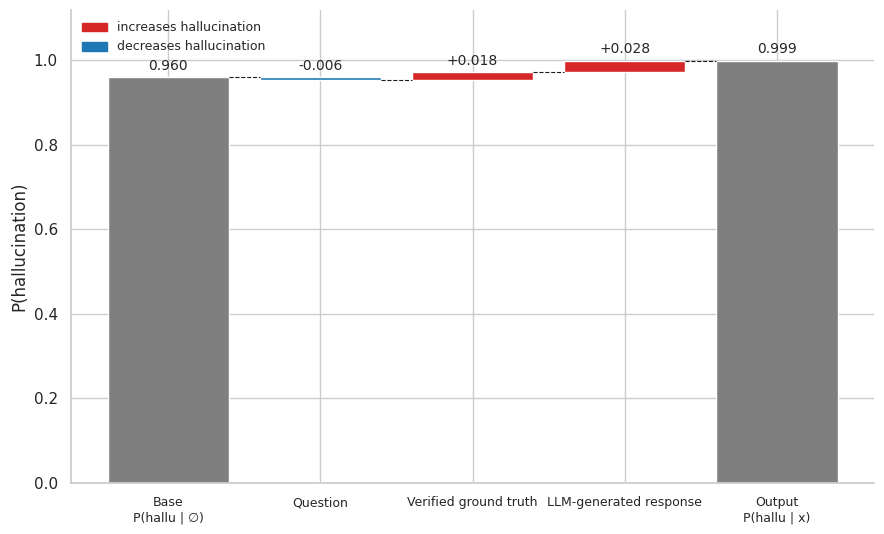

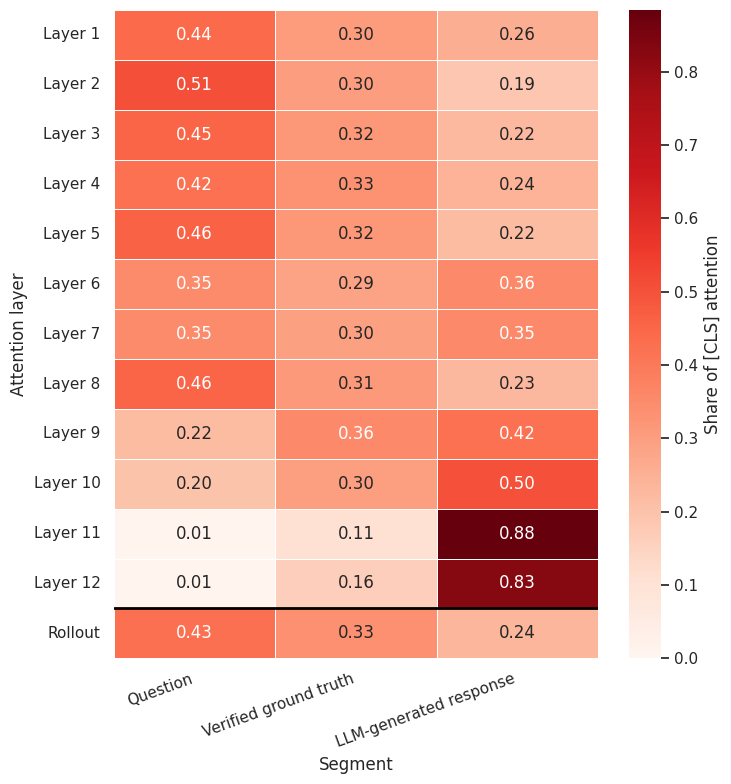


Base P(hallu)=0.9597  Output P(hallu)=0.9991
               segment  shapley_contribution  shapley_share  attention_rollout_share
              Question               -0.0062         0.1192                   0.4280
 Verified ground truth                0.0177         0.3428                   0.3350
LLM-generated response                0.0278         0.5380                   0.2371
Saved to: C:\Users\CH.SC.U4CSE23160\Neural Project\IndicHallbench-Hallucinations-Benchmark\results\muril_base_full_dataset\explainability\paper_figures


In [27]:
# ============================================================
# PAPER FIGURES 11 & 12
#   Fig. 11: SHAP-based explanation of a hallucination prediction,
#            contributions of Question, Verified ground truth and
#            LLM-generated response (waterfall from base to output).
#   Fig. 12: Attention heatmap distributing [CLS] attention across the
#            three segments, per layer, plus attention rollout, for the
#            same example.
#
# Run AFTER the explainability v2 cell (needs: model, tokenizer,
# test_df, predict_proba, hallu_score, exact_segment_shapley,
# get_attention, token_segments, attention_shares, SEGMENTS,
# IDX_CORRECT, EXPL_DIR, FONT_CHAIN).
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

plt.rcParams["font.family"] = FONT_CHAIN      # Indic-script safe
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

FIG_DIR = EXPL_DIR / "paper_figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Paper terminology (matches the captions)
SEG_LABELS = ["Question", "Verified ground truth", "LLM-generated response"]
SEG_KEYS = ["question", "ground_truth", "response"]      # same order as SEG_LABELS

# Representative example. None = automatic choice (see below).
REP_INDEX = 1118


# ------------------------------------------------------------
# 1. Choose the representative true-positive example
#    Automatic rule: among correctly detected hallucinations, take the
#    one whose P(hallucination) is closest to the median of that group.
#    This avoids cherry-picking an extreme case. Override REP_INDEX to
#    force a specific row.
# ------------------------------------------------------------
y_test = test_df["label"].to_numpy()
test_texts = test_df["input_text"].tolist()
pred_test = predict_proba(test_texts, model).argmax(1)
tp_idx = np.where((y_test != IDX_CORRECT) & (pred_test != IDX_CORRECT))[0]

if REP_INDEX is None:
    p_tp = hallu_score([test_texts[i] for i in tp_idx], model)
    rep = int(tp_idx[np.argmin(np.abs(p_tp - np.median(p_tp)))])
else:
    rep = int(REP_INDEX)

row = test_df.iloc[rep]
text = row["input_text"]
print(f"Representative example: test row {rep} | gold={row['correctness_label']} "
      f"| language={row['language']}")
print(text)


# ------------------------------------------------------------
# 2. Figure 11: segment-level SHAP waterfall
# ------------------------------------------------------------
phi, base_v, full_v = exact_segment_shapley(row, model)
vals = [phi[k] for k in SEG_KEYS]

labels = ["Base\nP(hallu | ∅)"] + SEG_LABELS + ["Output\nP(hallu | x)"]
fig, ax = plt.subplots(figsize=(9, 5.5))
cum = base_v
ax.bar(0, base_v, color="#7f7f7f")
ax.text(0, base_v + 0.01, f"{base_v:.3f}", ha="center", va="bottom", fontsize=10)
for k, v in enumerate(vals, start=1):
    bottom = cum if v >= 0 else cum + v
    ax.bar(k, abs(v), bottom=bottom,
           color="#d62728" if v >= 0 else "#1f77b4")
    ax.plot([k - 1 + 0.4, k - 0.4], [cum, cum], "k--", lw=0.8)
    ax.text(k, max(cum, cum + v) + 0.01, f"{v:+.3f}", ha="center",
            va="bottom", fontsize=10)
    cum += v
n = len(vals) + 1
ax.plot([n - 1 + 0.4, n - 0.4], [cum, cum], "k--", lw=0.8)
ax.bar(n, full_v, color="#7f7f7f")
ax.text(n, full_v + 0.01, f"{full_v:.3f}", ha="center", va="bottom", fontsize=10)

ax.set_xticks(range(n + 1))
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel("P(hallucination)")
ax.set_ylim(0, max(base_v, full_v, cum) + 0.12)
ax.legend(handles=[mpatches.Patch(color="#d62728", label="increases hallucination"),
                   mpatches.Patch(color="#1f77b4", label="decreases hallucination")],
          loc="upper left", fontsize=9, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig11_shap_segment_contributions.pdf", bbox_inches="tight")
plt.savefig(FIG_DIR / "fig11_shap_segment_contributions.png", dpi=600, bbox_inches="tight")
plt.show()

# Efficiency check: contributions must reconstruct the output exactly
assert abs(base_v + sum(vals) - full_v) < 1e-6


# ------------------------------------------------------------
# 3. Figure 12: attention distribution across segments, per layer
#    Head-averaged [CLS] attention, restricted to real tokens and
#    renormalised per layer; last row = attention rollout.
# ------------------------------------------------------------
tokens, offsets, A = get_attention(text)          # A: (L, H, T, T)
seg, special = token_segments(text, offsets)
real = (~special).astype(float)
L = A.shape[0]

M = np.zeros((L + 1, 3))
for l in range(L):
    cls = A[l].mean(axis=0)[0] * real             # [CLS] row, real tokens only
    tot = cls.sum()
    for s in range(3):
        M[l, s] = cls[seg == s].sum() / tot
M[L] = attention_shares(text)                      # rollout row

row_labels = [f"Layer {l + 1}" for l in range(L)] + ["Rollout"]
fig, ax = plt.subplots(figsize=(7.5, 8))
sns.heatmap(M, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=max(0.6, M.max()),
            xticklabels=SEG_LABELS, yticklabels=row_labels,
            cbar_kws={"label": "Share of [CLS] attention"}, ax=ax,
            linewidths=0.4, linecolor="white")
ax.axhline(L, color="black", lw=2)                 # separates rollout from layers
ax.set_xlabel("Segment")
ax.set_ylabel("Attention layer")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig12_attention_segment_heatmap.pdf", bbox_inches="tight")
plt.savefig(FIG_DIR / "fig12_attention_segment_heatmap.png", dpi=600, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------
# 4. Save the numbers behind both figures (for the text and reviewers)
# ------------------------------------------------------------
numbers = pd.DataFrame({
    "segment": SEG_LABELS,
    "shapley_contribution": vals,
    "shapley_share": shapley_share(phi),
    "attention_rollout_share": M[L],
})
numbers.to_csv(FIG_DIR / "fig11_fig12_values.csv", index=False)
print(f"\nBase P(hallu)={base_v:.4f}  Output P(hallu)={full_v:.4f}")
print(numbers.round(4).to_string(index=False))
print("Saved to:", FIG_DIR)

Representative TP: test row 6104 | language=HI-EN | gold=Partially Correct | P(hallucination)=0.997


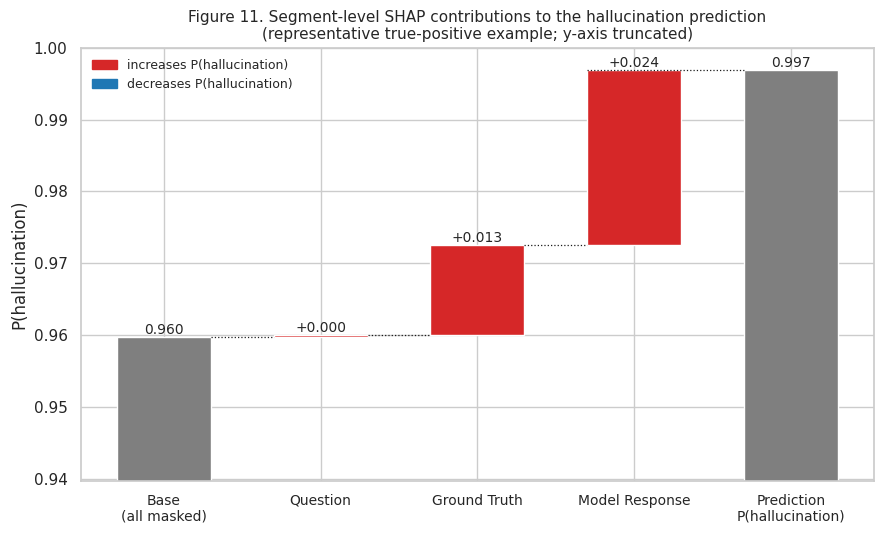

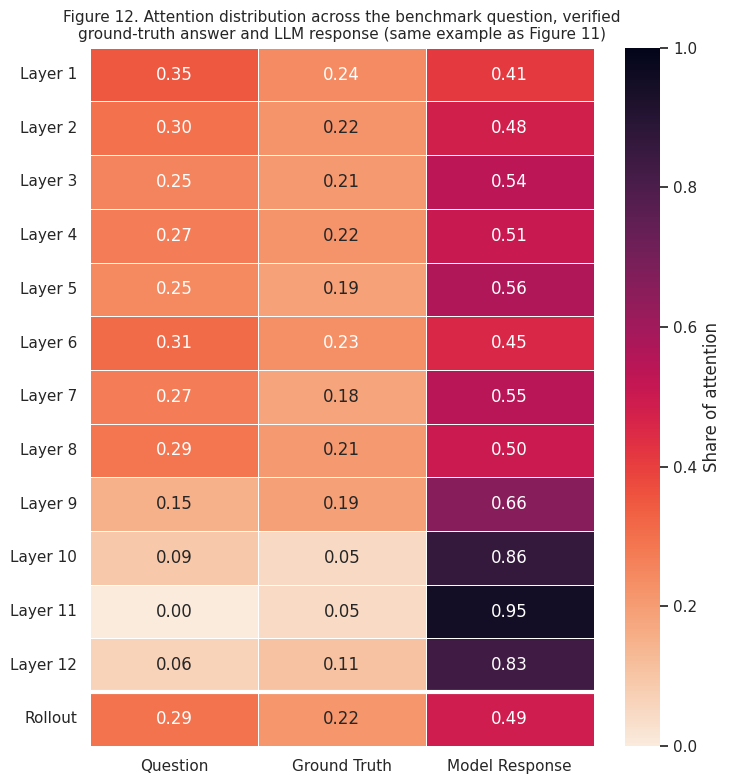

Figure 11 values: {'question': 0.0003, 'ground_truth': 0.0125, 'response': 0.0244} | base 0.9597 | prediction 0.9969
Figure 12 rollout shares: {'Question': np.float64(0.2941), 'Ground Truth': np.float64(0.2164), 'Model Response': np.float64(0.4895)}
Saved to: C:\Users\CH.SC.U4CSE23160\Neural Project\IndicHallbench-Hallucinations-Benchmark\results\muril_base_full_dataset\explainability\paper_figures


In [31]:
# ============================================================
# FIGURES 11 AND 12  (run after explainability_analysis_v2.py)
#
# Uses from the v2 cell: model, tokenizer, test_df, test_texts,
# hall_true, pred_base_test, IDX_CORRECT, SEGMENTS, SEG_HEADERS,
# SEG_NAMES, EXPL_DIR, FONT_CHAIN, exact_segment_shapley, hallu_score,
# get_attention, attention_rollout, token_segments, att_model.
#
# Representative example: the true-positive hallucination whose
# P(hallucination) is closest to the median of all true positives.
# This choice is deterministic and easy to state in the caption.
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

FIG_DIR = EXPL_DIR / "paper_figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams["font.family"] = FONT_CHAIN      # keeps Indic scripts rendering
plt.rcParams["pdf.fonttype"] = 42

# ------------------------------------------------------------
# 1. Select the representative true-positive example
# ------------------------------------------------------------
hall_true_arr = np.asarray(hall_true)
tp_idx = np.where(hall_true_arr & (pred_base_test != IDX_CORRECT))[0]
p_tp = hallu_score([test_texts[i] for i in tp_idx], model)
rep_pos = int(np.argmin(np.abs(p_tp - np.median(p_tp))))
rep_idx = int(tp_idx[rep_pos])
row = test_df.iloc[rep_idx]
text = row["input_text"]
print(f"Representative TP: test row {rep_idx} | language={row['language']} "
      f"| gold={row['correctness_label']} | P(hallucination)={p_tp[rep_pos]:.3f}")

# ------------------------------------------------------------
# 2. FIGURE 11: waterfall of exact segment Shapley contributions
#    Base  -> +phi(Question) -> +phi(Ground truth) -> +phi(Response) -> f(x)
#    Exact because the three segment values sum to f(x) - f(empty).
# ------------------------------------------------------------
phi, base_v, full_v = exact_segment_shapley(row, model)
assert abs(base_v + sum(phi.values()) - full_v) < 1e-6

steps = [SEG_HEADERS[k] for k in SEGMENTS]
values = [phi[k] for k in SEGMENTS]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.bar(0, base_v, color="#7f7f7f", width=0.6)
ax.text(0, base_v, f"{base_v:.3f}", ha="center", va="bottom", fontsize=10)

cum = base_v
for k, (name, val) in enumerate(zip(steps, values), start=1):
    bottom = min(cum, cum + val)
    ax.bar(k, abs(val), bottom=bottom, width=0.6,
           color="#d62728" if val > 0 else "#1f77b4")
    ax.hlines(cum, k - 1 + 0.3, k - 0.3, colors="k", linestyles=":", lw=0.9)
    ax.text(k, max(cum, cum + val), f"{val:+.3f}", ha="center",
            va="bottom", fontsize=10)
    cum += val
ax.hlines(cum, len(steps) + 0.7 - 1, len(steps) + 0.7, colors="k",
          linestyles=":", lw=0.9)

ax.bar(len(steps) + 1, full_v, color="#7f7f7f", width=0.6)
ax.text(len(steps) + 1, full_v, f"{full_v:.3f}", ha="center",
        va="bottom", fontsize=10)

ticks = ["Base\n(all masked)"] + steps + ["Prediction\nP(hallucination)"]
ax.set_xticks(range(len(ticks)))
ax.set_xticklabels(ticks, fontsize=10)
lo = min(base_v, full_v, base_v + min(0, sum(values)))
hi = max(base_v, full_v, base_v + max(0, sum(values)))
pad = max(0.02, 0.15 * (hi - lo))
ax.set_ylim(max(0, lo - pad), min(1, hi + pad))
ax.set_ylabel("P(hallucination)")
ax.set_title("Figure 11. Segment-level SHAP contributions to the hallucination "
             "prediction\n(representative true-positive example; y-axis truncated)",
             fontsize=11)
ax.legend(handles=[
    plt.Rectangle((0, 0), 1, 1, color="#d62728", label="increases P(hallucination)"),
    plt.Rectangle((0, 0), 1, 1, color="#1f77b4", label="decreases P(hallucination)"),
], loc="upper left", fontsize=9, frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "figure_11_shap_waterfall.png", dpi=300, bbox_inches="tight")
plt.savefig(FIG_DIR / "figure_11_shap_waterfall.pdf", bbox_inches="tight")
plt.show()

pd.DataFrame([{"base": base_v, **{f"phi_{k}": phi[k] for k in SEGMENTS},
               "prediction": full_v, "test_row": rep_idx,
               "language": row["language"], "gold": row["correctness_label"]}]
             ).to_csv(FIG_DIR / "figure_11_values.csv", index=False)

# ------------------------------------------------------------
# 3. FIGURE 12: attention heatmap over the three segments
#    Rows: transformer layers 1..L (head-averaged [CLS] attention,
#          normalised over real tokens so each row sums to 1)
#          plus a final row with attention-rollout shares.
#    Columns: Question | Ground truth | Model response.
# ------------------------------------------------------------
tokens, offsets, A = get_attention(text, att_model)
seg, special = token_segments(text, offsets)
real = ~special
L = A.shape[0]

cls_layers = A.mean(axis=1)[:, 0, :]                      # (L, T)
layer_mat = np.zeros((L, 3))
for l in range(L):
    v = cls_layers[l] * real
    tot = v.sum()
    for s in range(3):
        layer_mat[l, s] = v[(seg == s) & real].sum() / tot

rollout = attention_rollout(A)
roll_row = np.array([rollout[(seg == s) & real].sum() for s in range(3)])
roll_row = roll_row / roll_row.sum()

heat = np.vstack([layer_mat, roll_row])
row_labels = [f"Layer {l + 1}" for l in range(L)] + ["Rollout"]

fig, ax = plt.subplots(figsize=(7.5, 8))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="rocket_r", vmin=0, vmax=1,
            xticklabels=[SEG_NAMES[s] for s in range(3)],
            yticklabels=row_labels, cbar_kws={"label": "Share of attention"},
            linewidths=0.4, linecolor="white", ax=ax)
ax.axhline(L, color="white", lw=3)                        # separate rollout row
ax.set_title("Figure 12. Attention distribution across the benchmark question, "
             "verified\nground-truth answer and LLM response (same example as Figure 11)",
             fontsize=11)
ax.set_xlabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "figure_12_attention_heatmap.png", dpi=300, bbox_inches="tight")
plt.savefig(FIG_DIR / "figure_12_attention_heatmap.pdf", bbox_inches="tight")
plt.show()

pd.DataFrame(heat, columns=SEG_NAMES, index=row_labels).round(4).to_csv(
    FIG_DIR / "figure_12_values.csv")

print("Figure 11 values:", {k: round(v, 4) for k, v in phi.items()},
      "| base", round(base_v, 4), "| prediction", round(full_v, 4))
print("Figure 12 rollout shares:", dict(zip(SEG_NAMES, np.round(roll_row, 4))))
print("Saved to:", FIG_DIR)